In [23]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import matplotlib.colors as colors
from matplotlib.lines import Line2D
import pandas as pd
from scipy.stats.mstats import gmean
import os as os
import glob
import sys
import re
import argparse
import gzip
from contextlib import contextmanager


# Constants

In [24]:
h_pl = 6.62607015e-34 # Planck constant [J s]
c_light = 299792458 # Speed of light [m/s]
kb = 1.380649e-23 # Boltzmann constant [J/K]
Rd = 287 # Specific gas constant of dry air [J/(Kg K)]
Rv = 461.5 # Specific gas constant of water vapor [J/(Kg K)]
T0 = 300 # Arbitrary reference temperature [K] 
e0 = 3525 # Saturation vapor pressure at T0 [Pa]
gamma_wv = 18 # Power law exponent of temperature - satuation vapor pressure relation []
Lv = 2492100 # Latent heat of vaporization of water at T0 [J/kg]
ps = 101325 # Mean sea level pressure [Pa]
cp = 1003.5 # Specific heat of dry air at constant pressure [J / (Kg K)]
g = 9.81 # Average gravity on Earth [m/s^2]
pi = scipy.constants.pi

qco2 = 400e-6
RH = 0.5

In [25]:
nu_rot = 150 * 100 # Middle of the rotation band [1/m]
nu_vr = 1500 * 100 # Middle of the vibration-rotation band [1/m]
nu_co2 = 667.5 * 100 # Middle of the CO2 band [1/m]

cos_theta = 3/5 # Inverse angular diffusivity factor []
p0 = 100000 # Reference pressure for the absorption coefficients [Pa]
nu_min = 1 * 100
nu_max = 2000 * 100

# Idealized atmosphere

In [108]:
def Specific_humidity(p, Ts, Ttp, RH):
    Tav = (Ts + Ttp)/2
    qs_sat = Rd/Rv * e0/ps * (Ts/T0)**gamma_wv
    gamma_lr = Rd * Tav * np.log(Ts/Ttp) / (cp * (Ts - Ttp) + Lv * qs_sat)
    T = Ts * (p/ps) ** gamma_lr # Note that T is not fixed here in the stratosphere.
    q = RH * Rd/Rv * e0/p * (T/T0)**gamma_wv
    return q

#Temperature [K] as function of surface temperature [K]
def Temperature(p, Ts, Ttp):
    Tav = (Ts + Ttp)/2
    T = np.ones_like(p) * Ttp
    qs_sat = Rd/Rv * e0/ps * (Ts/T0)**gamma_wv
    gamma_lr = Rd * Tav * np.log(Ts/Ttp) / (cp * (Ts - Ttp) + Lv * qs_sat)
    H = Rd * Tav / g
    z_tp = (cp * (Ts - Ttp) + Lv * qs_sat)/g # Tropopause height [m]
    p_tp = ps* np.exp(-z_tp/H) # Pressure of the tropopause [Pa]
    T[p>p_tp] = Ts * (p[p>p_tp]/ps) ** gamma_lr
    return T

In [110]:
# Half levels correspond to the upper and lower boundary of each atmospheric layer, while full levels correspond to the level in the middle of each layer. 
def atmosphere(Ts, RH):
    number_intervals = 100

    Ttp = 2/3 * Ts
    
    p_min = 1
    p_max = ps
    p_half = np.linspace(p_min,p_max, number_intervals + 1)
    p = (p_half[1:] + p_half[:-1])/2
    
    T_half = Temperature(p_half, Ts, Ttp)
    q_half = Specific_humidity(p_half, Ts, Ttp, RH)
    
    T = (T_half[1:] + T_half[:-1])/2
    q = (q_half[1:] + q_half[:-1])/2
    return T, T_half, q, q_half, p, p_half

# Absorption

In [29]:
# Pressure dependence is included in Q(p,q)
def k_h2o(nu):
    return np.max((kappa_rot * np.exp(-np.abs(nu-nu_rot)/l_rot), kappa_vr * np.exp(-np.abs(nu-nu_vr)/l_vr)),axis=0)

def k_co2(nu):
    return kappa_co2 * np.exp(-np.abs(nu-nu_co2)/l_co2)

# Optical depth

In [30]:
# Total atmospheric path
def total_pq(p, q):
    delta_p = np.concatenate((p[0].reshape(1), p[1:] - p[:-1]))
    trapeizodal_pq = np.concatenate(((p[0]*q[0]/2).reshape(1), (p[:-1]*q[:-1] + p[1:]*q[1:])/2))
    return np.cumsum((1/(g * p0 * cos_theta) * delta_p * trapeizodal_pq))

# Atmospheric path for a single layer
def local_pq(p, q):
    delta_p =  p[1:] - p[:-1]
    trapeizodal_pq = (p[:-1]*q[:-1] + p[1:]*q[1:])/2
    return 1/(g * p0 * cos_theta) * delta_p * trapeizodal_pq


In [289]:
# All tau corresponding to 
def tau_inverse_h2o(pq, tau):
    nu1 = - l_rot * np.log(pq * kappa_rot) + nu_rot + l_rot * np.log(tau) 
    nu2 =  l_rot * np.log(pq * kappa_rot) + nu_rot - l_rot * np.log(tau)
    nu3 = - l_vr * np.log(pq * kappa_vr) + nu_vr + l_vr * np.log(tau)
    nu4 =  l_vr * np.log(pq * kappa_vr) + nu_vr - l_vr * np.log(tau)
    mask1 = (nu_min < nu1) & (nu1 < nu_rot)
    mask2 = (nu_rot <= nu2) & (nu2 < nu_mid)
    mask3 = (nu_mid <= nu3) & (nu3 < nu_vr)
    mask4 = (nu_vr <= nu4) & (nu4 < nu_max)
    nu1[~mask1] = -1;
    nu2[~mask2] = -1;
    nu3[~mask3] = -1;
    nu4[~mask4] = -1;
    return np.stack([nu1, nu2, nu3, nu4],axis=0)

def tau_inverse_co2(pq, tau):
    nu1 = - l_co2 * np.log(pq * kappa_co2) + nu_co2 + l_co2 * np.log(tau) 
    nu2 =  l_co2 * np.log(pq * kappa_co2) + nu_co2 - l_co2 * np.log(tau)
    mask1 = (nu_min < nu1) & (nu1 < nu_co2)
    mask2 = (nu_co2 <= nu2) & (nu2 < nu_max)
    nu1[~mask1] = -1;
    nu2[~mask2] = -1;
    return np.stack([nu1, nu2],axis=0)

# Transmissivity

In [291]:
def trans_inverse_h2o(pq, trans):
    nu1 = - l_rot * np.log(pq * kappa_rot) + nu_rot + l_rot * np.log(np.abs(np.log(trans[0])))
    nu2 =  l_rot * np.log(pq * kappa_rot) + nu_rot - l_rot * np.log(np.abs(np.log(trans[1])))
    nu3 = - l_vr * np.log(pq * kappa_vr) + nu_vr + l_vr * np.log(np.abs(np.log(trans[2])))
    nu4 =  l_vr * np.log(pq * kappa_vr) + nu_vr - l_vr * np.log(np.abs(np.log(trans[3])))
    mask1 = (nu_min < nu1) & (nu1 < nu_rot)
    mask2 = (nu_rot <= nu2) & (nu2 < nu_mid)
    mask3 = (nu_mid <= nu3) & (nu3 < nu_vr)
    mask4 = (nu_vr <= nu4) & (nu4 < nu_max)
    nu1[~mask1] = -1;
    nu2[~mask2] = -1;
    nu3[~mask3] = -1;
    nu4[~mask4] = -1;
    return np.stack([nu1, nu2, nu3, nu4],axis=0)

def trans_inverse_co2(pq, trans):
    nu1 = - l_co2 * np.log(pq * kappa_co2) + nu_co2 + l_co2 * np.log(np.abs(np.log(trans[0])))
    nu2 =  l_co2 * np.log(pq * kappa_co2) + nu_co2 - l_co2 * np.log(np.abs(np.log(trans[1])))
    mask1 = (nu1 < nu_co2)
    mask2 = (nu_co2 <= nu2)
    nu1[~mask1] = -1;
    nu2[~mask2] = -1;
    return np.stack([nu1, nu2],axis=0)
    
def trans_malkmus(tau, gamma):
        if isinstance(gamma, np.ndarray):
            gamma = gamma.reshape(-1,1)
        c = np.pi * gamma / 4
        tau_hat = np.sqrt((tau + c) * c)
        return np.exp(-2 * (tau_hat - c))

# Planck function

In [33]:
# Planck function as function of wavenumber [1/cm] and temperature [K]
def B(nu, T):
    return 2 * h_pl * c_light ** 2 * nu ** 3 /(np.exp(h_pl * c_light * nu / (kb * T)) - 1)

# CTS

In [34]:
# CTS for a given transmissivity
def cts_trans_nu(p_half, q_half, T, trans, nu):
  
    C = -np.pi * g / cp
      
    dtransp = (trans[1:] - trans[:-1]) / (p_half[1:].reshape(-1,1) - p_half[:-1].reshape(-1,1))
    HR_nu = C * B(nu.reshape(1,-1), T.reshape(-1,1)) * dtransp
    return HR_nu

def cts_trans(p_half, q_half, T, trans, nu):
    delta_nu = nu[1:] - nu[:-1]
    integrand = cts_trans_nu(p_half, q_half, T, trans, nu)
    
    # Cooling rate over each band
    HR = np.sum((integrand[:,1:] + integrand[:,:-1])/2 * delta_nu, axis=-1)
    return HR

## H2O

In [35]:
# Reference
def cts_h2o(p_half, q_half, T):
    pq = local_pq(p_half, q_half)

    # Wavenumber grid
    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))

    # Absorption bands
    nus_rot_left = nu[(nu <= nu_rot)]
    nus_rot_right = nu[(nu_rot <= nu) & (nu <= nu_mid)]
    nus_vr_left = nu[(nu_mid <= nu) & (nu <= nu_vr)]
    nus_vr_right = nu[(nu_vr <= nu)]
    
    C = -np.pi * g / cp
    # Grid spacing for the wavenumber grid
    delta_nu = nu[1] - nu[0]
    
    HR_band = np.zeros((4,pq.shape[0]))

    for k, nus in enumerate([nus_rot_left,nus_rot_right, nus_vr_left,nus_vr_right]):
        
        tau = np.insert(np.cumsum(pq.reshape(-1,1) * k_h2o(nus).reshape(1,-1), axis = 0), 0, 0, axis=0)
        trans = np.exp(-tau)
        dtransp = (trans[1:] - trans[:-1]) / (p_half[1:].reshape(-1,1) - p_half[:-1].reshape(-1,1))
        integrand = C * B(nus.reshape(1,-1), T.reshape(-1,1)) * dtransp
        
        # Cooling rate over each band
        HR_band[k] = np.sum((integrand[:,1:] + integrand[:,:-1])/2 * delta_nu, axis=-1)
    return HR_band

# tau = 1
def cts_tau1_h2o(p,p_half,q, q_half,T,T_half):

    pq = total_pq(p,q)
    nu = tau_inverse_h2o(pq, 1)
    C = np.pi * p * q/(cp*p0*cos_theta*pq)

    mask0 = (nu[0] != -1)
    mask1 = (nu[1] != -1)
    mask2 = (nu[2] != -1)
    mask3 = (nu[3] != -1)

    H1 = np.zeros_like(p)
    H2 = np.zeros_like(p)
    H3 = np.zeros_like(p)
    H4 = np.zeros_like(p)

    H1[mask0] = C[mask0] * l_rot * B(nu[0][mask0], T[mask0])
    H2[mask1] = C[mask1] * l_rot * B(nu[1][mask1], T[mask1])
    H3[mask2] = C[mask2] * l_vr  * B(nu[2][mask2], T[mask2])
    H4[mask3] = C[mask3] * l_vr  * B(nu[3][mask3], T[mask3]) 
    
    HR_band = np.zeros((4,p.shape[0]))
    HR_band[0] = H1
    HR_band[1] = H2
    HR_band[2] = H3
    HR_band[3] = H4
    return HR_band

# midpoint
def cts_transmid_h2o(p,p_half,q, q_half,T,T_half):

    pq = total_pq(p,q)
    C = np.pi * p * q/(cp*p0*cos_theta*pq)

    tau_rot_left_min = pq * k_h2o(nu_min)
    tau_rot_right_min = pq * k_h2o(nu_mid)
    tau_rot_max = pq * kappa_rot
    tau_vr_left_min = pq * k_h2o(nu_mid)
    tau_vr_right_min = pq * k_h2o(nu_max)
    tau_vr_max = pq * kappa_vr

    trans_nu = np.zeros((4,p.size))
    trans_nu[0] = (np.exp(-tau_rot_left_min) + np.exp(-tau_rot_max))/2
    trans_nu[1] = (np.exp(-tau_rot_right_min) + np.exp(-tau_rot_max))/2
    trans_nu[2] = (np.exp(-tau_vr_left_min) + np.exp(-tau_vr_max))/2
    trans_nu[3] = (np.exp(-tau_vr_right_min) + np.exp(-tau_vr_max))/2

    nu = trans_inverse_h2o(pq, trans_nu)

    delta_rot_left = np.exp(-tau_rot_left_min) - np.exp(-tau_rot_max)
    delta_rot_right = np.exp(-tau_rot_right_min) - np.exp(-tau_rot_max)
    delta_vr_left = np.exp(-tau_vr_left_min) - np.exp(-tau_vr_max)
    delta_vr_right = np.exp(-tau_vr_right_min) - np.exp(-tau_vr_max)

    H1 = C * l_rot * B(nu[0], T) * delta_rot_left
    H2 = C * l_rot * B(nu[1], T) * delta_rot_right
    H3 = C * l_vr  * B(nu[2], T) * delta_vr_left
    H4 = C * l_vr  * B(nu[3], T) * delta_vr_right
    
    HR_band = np.zeros((4,p.shape[0]))
    HR_band[0] = H1
    HR_band[1] = H2
    HR_band[2] = H3
    HR_band[3] = H4
    return HR_band



## CO2

In [36]:
# Reference
def cts_co2(p_half, q_co2, T):
    pq = local_pq(p_half, q_co2 + np.zeros_like(p_half))

    # Wavenumber grid
    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))

    # Absorption bands
    nus_co2_left = nu[(nu <= nu_co2)]
    nus_co2_right = nu[(nu_co2 <= nu)]

    
    C = -np.pi * g / cp
    # Grid spacing for the wavenumber grid
    delta_nu = nu[1] - nu[0]
    
    HR_band = np.zeros((2,pq.shape[0]))

    for k, nus in enumerate([nus_co2_left,nus_co2_right]):
        
        tau = np.insert(np.cumsum(pq.reshape(-1,1) * k_co2(nus).reshape(1,-1), axis = 0), 0, 0, axis=0)
        trans = np.exp(-tau)
        dtransp = (trans[1:] - trans[:-1]) / (p_half[1:].reshape(-1,1) - p_half[:-1].reshape(-1,1))
        integrand = C * B(nus.reshape(1,-1), T.reshape(-1,1)) * dtransp
        
        # Cooling rate over each band
        HR_band[k] = np.sum((integrand[:,1:] + integrand[:,:-1])/2 * delta_nu, axis=-1)
    return HR_band

# tau = 1
def cts_tau1_co2(p,p_half,q_co2,T,T_half):

    pq = total_pq(p,q_co2 + np.zeros_like(p))
    nu = tau_inverse_co2(pq, 1)
    C = np.pi * p * q_co2/(cp*p0*cos_theta*pq)

    mask0 = (nu[0] != -1)
    mask1 = (nu[1] != -1)
    
    H1 = np.zeros_like(p)
    H2 = np.zeros_like(p)

    H1[mask0] = C[mask0] * l_co2 * B(nu[0][mask0], T[mask0])
    H2[mask1] = C[mask1] * l_co2 * B(nu[1][mask1], T[mask1])
    
    HR_band = np.zeros((4,p.shape[0]))
    HR_band[0] = H1
    HR_band[1] = H2
    return HR_band

# midpoint
def cts_transmid_co2(p,p_half,q_co2,T,T_half):

    pq = total_pq(p,q_co2 + np.zeros_like(p))
    nu =  np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    C = np.pi * p * q_co2/(cp*p0*cos_theta*pq)

    mask1 = (nu < nu_co2)
    mask2 = (nu_co2 <= nu) 
    
    tau_co2_left_min = pq * k_co2(nu_min)
    tau_co2_right_min = pq * k_co2(nu_max)
    tau_co2_max = pq * kappa_co2

    delta_co2_left = (np.exp(-tau_co2_left_min) - np.exp(-tau_co2_max))
    delta_co2_right = (np.exp(-tau_co2_right_min) - np.exp(-tau_co2_max))

    trans_nu = np.zeros((2,p.size))
    trans_nu[0] = (np.exp(-tau_co2_left_min) + np.exp(-tau_co2_max))/2
    trans_nu[1] = (np.exp(-tau_co2_right_min) + np.exp(-tau_co2_max))/2

    nu = trans_inverse_co2(pq, trans_nu)


    H1 = C * l_co2 * B(nu[0], T) * delta_co2_left
    H2 = C * l_co2 * B(nu[1], T) * delta_co2_right

    HR_band = np.zeros((2,p.shape[0]))
    HR_band[0] = H1
    HR_band[1] = H2
    return HR_band



# OLR

In [259]:
# OLR for a given transmissivity
def olr_trans(p_half, q_half, T, T_half, trans, nu):
    
    integrand = np.pi * B(nu.reshape(1,-1), T.reshape(-1,1)) * (trans[:-1] - trans[1:])

    olr_atm = np.sum(integrand, axis=0)
    olr_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1)) * trans[-1].reshape(1,-1)).ravel()
    return olr_atm, olr_surf

## H2O

In [256]:
# Reference
def olr_h2o(p_half, q_half, T, T_half):
    pq = local_pq(p_half, q_half)
    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    tau_local = pq.reshape(-1,1) * k_h2o(nu).reshape(1,-1)
    tau = np.cumsum(tau_local, axis = 0)
    tau = np.insert(tau, 0, 0, axis = 0)
    trans = np.exp(-tau)
    integrand = np.pi * B(nu.reshape(1,-1), T.reshape(-1,1)) * (trans[:-1] - trans[1:]) 
    
    olr_atm = np.sum(integrand, axis=0)
    olr_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1)) * trans[-1].reshape(1,-1)).ravel()
    return olr_atm, olr_surf

# tau = 1
def olr_tau1_h2o(p_half, q_half, T):
    pq = local_pq(p_half, q_half)
    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    tau_local = pq.reshape(-1,1) * k_h2o(nu).reshape(1,-1)
    tau = np.cumsum(tau_local, axis = 0)

    mask = tau[-1] >= 1
    
    i_tau1 = np.argmin(np.abs(tau - 1), axis = 0)
    p_nu = np.stack([i_tau1[mask], np.arange(0,tau.shape[1])[mask]])

    
    integrand =  np.pi* B(nu.reshape(1,-1), T.reshape(-1,1)) 
    integrand_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1))).ravel()

    olr_atm = np.zeros(integrand.shape[1])
    olr_surf = np.zeros(integrand.shape[1])

    olr_atm[mask] = integrand[*p_nu]
    olr_surf[~mask] = integrand_surf[~mask]
    return olr_atm, olr_surf

# midpoint
def olr_transmid_h2o(p_half, q_half, T):
    pq = local_pq(p_half, q_half)
    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    tau_local = pq.reshape(-1,1) * k_h2o(nu).reshape(1,-1)
    tau = np.cumsum(tau_local, axis = 0)
    
    trans = np.exp(-tau)
    trans_max = trans[0,:]
    trans_min = trans[-1,:]

    i_mid = np.argmin(np.abs(trans - (trans_max + trans_min)/2), axis = 0)
    p_nu = np.stack([i_mid, np.arange(0,tau.shape[1])])
    
    integrand =  np.pi* B(nu.reshape(1,-1), T.reshape(-1,1)) * (trans_max - trans_min)
    olr_atm = integrand[*p_nu]
    olr_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1)) * trans[-1].reshape(1,-1)).ravel()

    return olr_atm, olr_surf


## CO2

In [257]:
# Reference
def olr_co2(p_half, q_half, T, T_half):
    pq_co2 = local_pq(p_half, qco2 + np.zeros_like(q_half))

    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    tau_local = (pq_co2.reshape(-1,1) * k_co2(nu).reshape(1,-1) )
    tau = np.cumsum(tau_local, axis = 0)
    tau = np.insert(tau, 0, 0, axis = 0)
    trans = np.exp(-tau)
    integrand = np.pi * B(nu.reshape(1,-1), T.reshape(-1,1)) * (trans[:-1] - trans[1:]) 
    olr_atm = np.sum(integrand, axis=0)
    olr_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1)) * trans[-1].reshape(1,-1)).ravel()

    return olr_atm, olr_surf

# tau = 1
def olr_tau1_co2(p_half, q_half, T):
    pq_co2 = local_pq(p_half, qco2 + np.zeros_like(q_half))
    
    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    tau_local = pq_co2.reshape(-1,1) * k_co2(nu).reshape(1,-1) 
    tau = np.cumsum(tau_local, axis = 0)

    mask = tau[-1] >= 1
    
    i_tau1 = np.argmin(np.abs(tau - 1), axis = 0)
    p_nu = np.stack([i_tau1[mask], np.arange(0,tau.shape[1])[mask]])

    integrand =  np.pi* B(nu.reshape(1,-1), T.reshape(-1,1)) 
    integrand_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1))).ravel()

    olr_atm = np.zeros(integrand.shape[1])
    olr_surf = np.zeros(integrand.shape[1])

    olr_atm[mask] = integrand[*p_nu]
    olr_surf[~mask] = integrand_surf[~mask]
    return olr_atm, olr_surf

# midpoint
def olr_transmid_co2(p_half, q_half, T):
    pq_co2 = local_pq(p_half, qco2 + np.zeros_like(q_half))
    
    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    tau_local = pq_co2.reshape(-1,1) * k_co2(nu).reshape(1,-1) 
    tau = np.cumsum(tau_local, axis = 0)
    
    trans = np.exp(-tau)
    trans_max = trans[0,:]
    trans_min = trans[-1,:]

    i_mid = np.argmin(np.abs(trans - (trans_max + trans_min)/2), axis = 0)
    p_nu = np.stack([i_mid, np.arange(0,tau.shape[1])])
    
    integrand =  np.pi* B(nu.reshape(1,-1), T.reshape(-1,1)) * (trans_max - trans_min)

    olr_atm = integrand[*p_nu]
    olr_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1)) * trans[-1].reshape(1,-1)).ravel()
    return olr_atm, olr_surf


## H2O + CO2

In [271]:
def olr_h2o_co2(p_half, q_half, T, T_half):
    pq_h2o_band = local_pq(p_half, q_half)
    pq_co2 = local_pq(p_half, qco2 + np.zeros_like(q_half))

    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    tau_local = (pq_h2o_band.reshape(-1,1) * k_h2o(nu).reshape(1,-1)  
               + pq_co2.reshape(-1,1) * k_co2(nu).reshape(1,-1))
    tau = np.cumsum(tau_local, axis = 0)
    tau = np.insert(tau, 0, 0, axis = 0)
    trans = np.exp(-tau)
    integrand = np.pi * B(nu.reshape(1,-1), T.reshape(-1,1)) * (trans[:-1] - trans[1:])
    olr_atm = np.sum(integrand, axis=0)
    olr_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1)) * trans[-1].reshape(1,-1)).ravel()
    return olr_atm, olr_surf

# tau = 1
def olr_tau1_h2o_co2(p_half, q_half, T):
    pq_h2o_band = local_pq(p_half, q_half)
    pq_co2 = local_pq(p_half, qco2 + np.zeros_like(q_half))
    
    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    tau_local = (pq_h2o_band.reshape(-1,1) * k_h2o(nu).reshape(1,-1)  
               + pq_co2.reshape(-1,1) * k_co2(nu).reshape(1,-1))
    tau = np.cumsum(tau_local, axis = 0)

    mask = tau[-1] >= 1
    i_tau1 = np.argmin(np.abs(tau - 1), axis = 0)
    p_nu = np.stack([i_tau1[mask], np.arange(0,tau.shape[1])[mask]])
    
    integrand =  np.pi* B(nu.reshape(1,-1), T.reshape(-1,1)) 
    integrand_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1))).ravel()

    olr_atm = np.zeros(integrand.shape[1])
    olr_surf = np.zeros(integrand.shape[1])

    olr_atm[mask] = integrand[*p_nu]
    olr_surf[~mask] = integrand_surf[~mask]
    return olr_atm, olr_surf

# midpoint
def olr_transmid_h2o_co2(p_half, q_half, T):
    pq_h2o_band = local_pq(p_half, q_half)
    pq_co2 = local_pq(p_half, qco2 + np.zeros_like(q_half))
    
    nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
    tau_local = (pq_h2o_band.reshape(-1,1) * k_h2o(nu).reshape(1,-1)  
               + pq_co2.reshape(-1,1) * k_co2(nu).reshape(1,-1))
    tau = np.cumsum(tau_local, axis = 0)
    
    trans = np.exp(-tau)
    trans_max = trans[0,:]
    trans_min = trans[-1,:]

    i_mid = np.argmin(np.abs(trans - (trans_max + trans_min)/2), axis = 0)
    p_nu = np.stack([i_mid, np.arange(0,tau.shape[1])])
    
    integrand =  np.pi* B(nu.reshape(1,-1), T.reshape(-1,1)) * (trans_max - trans_min)

    olr_atm = integrand[*p_nu]
    olr_surf = (np.pi * B(nu.reshape(1,-1), T_half[-1].reshape(-1,1)) * trans[-1].reshape(1,-1)).ravel()
    return olr_atm, olr_surf




# Atmosphere for the 4a line-by-line data

In [47]:
def parse_atmosphere_file(filepath):
    """
    Parse an atmospheric profile file.
    Returns a DataFrame with the profile data and a dict of metadata.
    """
    with open(filepath, "r") as f:
        lines = f.readlines()

    # --- Parse the header line ---
    header = lines[0].split()
    n_levels      = int(header[0])
    T_surface     = float(header[5])
    P_surface     = float(header[6])

    metadata = {
        "n_levels":    n_levels,
        "T_surface":   T_surface,
        "P_surface":   P_surface,
    }

    # --- Parse the data lines ---
    records = []
    for line in lines[1:n_levels + 1]:
        values = line.split()
        records.append({
            "pressure":          float(values[0]),
            "temperature":       float(values[1]),
            "specific_humidity": float(values[2]),
            "o3_mass_fraction":  float(values[3]),
        })

    df = pd.DataFrame(records)
    return df, metadata


In [48]:
def atmosphere_4a():
    # df_atm, meta = parse_atmosphere_file("lbl_data/atm4afmt_Koll2023.dsf")
    df_atm, meta = parse_atmosphere_file("lbl_data/atm4afmt_idealized_atmosphere.dsf")
    p_half          = df_atm["pressure"].values * 100        # shape: (n_levels,)
    T_half       = df_atm["temperature"].values.copy()     # shape: (n_levels,)
    q_half = df_atm["specific_humidity"].values # shape: (n_levels,)
    p_half[-1] = meta["P_surface"] * 100
    T_half[-1] = meta["T_surface"]
    p = (p_half[1:] + p_half[:-1])/2
    T = (T_half[1:] + T_half[:-1])/2
    q = (q_half[1:] + q_half[:-1])/2
    return T, T_half, q, q_half, p, p_half

# Open the line-by-line data

In [49]:


@contextmanager
def open_txt(chemin, mode='r', encoding='utf-8'):
    if chemin.endswith('.gz'):
        with gzip.open(chemin, mode + 't', encoding=encoding) as f:
            yield f
    else:
        with open(chemin, mode, encoding=encoding) as f:
            yield f

def parse_fortran_float(val_str):
    """
    Converts a Fortran string to a Python float.
    Handles ‘NaN’ values and scientific notation that omits the ‘E’.
    """
    val_str = val_str.strip()
    if val_str.upper() == 'NAN':
        return float('nan')
    
    # Si le format scientifique n'a pas de 'E', on l'ajoute.
    if 'E' not in val_str.upper():
        val_str = re.sub(r'(?<=\d)([-+])(?=\d+)', r'E\1', val_str)
        
    return float(val_str)

def parse_fortran_float_line(line):
    """
    Converts a Fortran string to a Python float.
    Handles ‘NaN’ values and scientific notation that omits the ‘E’.
    """
    parts = line.split()
    x_tmp = np.zeros(len(parts), dtype="float64")
    for ip, part in enumerate(parts):
        x_tmp[ip] = parse_fortran_float(part)

    return x_tmp

def read_properties(fname):
    """read the dto 4A file, and provides the numbert of lines,
    vertical levels, and frequences in the file
    """
    with open_txt(fname) as df:
        line = df.readline().strip()
        tot_nb_lines = 0
        tot_nb_freqs = 0
        nb_blocks = 0

        while line:
            parts = line.split()
            tot_nb_lines += 1
            if parts[0] != "#":
                print("ERROR, line should start with #, line:",tot_nb_lines)
                print(line)
                sys.exit()
            nb_freqs = int(parts[1])
            nb_levs = int(parts[2])
            nb_blocks += 1

            # read the top, mid, bottom pressure of each level
            # read the transmissions
            nb_pres_ar = 3
            for jp in range(nb_pres_ar+nb_freqs):
                line = df.readline().strip()
            tot_nb_freqs += nb_freqs
            tot_nb_lines += nb_pres_ar+nb_freqs
            line = df.readline().strip()

    prop = {"nb_lines":tot_nb_lines, "nb_levs": nb_levs
            ,"nb_freqs":tot_nb_freqs, "nb_blocks": nb_blocks}
    return prop

def read_tau(fname):

    prop = read_properties(fname)
    nb_pres_ar = 3
    pres = np.full([prop["nb_levs"],nb_pres_ar],float("nan"))
    tau = np.full([prop["nb_levs"]-1,prop["nb_freqs"]],float("nan"),dtype="float64")
    trans = np.full([prop["nb_levs"]-1,prop["nb_freqs"]],float("nan"))
    nu = np.full(prop["nb_freqs"],float("nan"))
                    
    jf_cum = 0 # index of the concatenated frequencies
    
    with open_txt(fname) as df:

        for jblock in range(prop["nb_blocks"]):

            # read line starting with #
            line = df.readline().strip()
            parts = line.split()
            nb_freqs = int(parts[1])

            # read the top, mid, bottom pressure of each level
            for jp in range(nb_pres_ar):
                line = df.readline().strip()
                if jblock == 0:
                    pres[:,jp] = parse_fortran_float_line(line)
                
            # read the transmissions, compute the optical thickness
            for jf in range(nb_freqs):
                line = df.readline().strip()
                xxx =  parse_fortran_float_line(line)
                nu[jf_cum] = xxx[0]
                # tau[:,jf_cum] = -np.log(np.maximum(xxx[2:],0))
                # trans[:,jf_cum] = xxx[2:]
                tau[:,jf_cum] = xxx[2:]*1.E6
                trans[:,jf_cum] = np.exp(-tau[:,jf_cum])
                jf_cum += 1
    return nu,tau, trans, pres


# Figures 

## Values H2O

In [50]:
nu, tau, trans, pres = read_tau("lbl_data/dto1_4asub1fmt_idealized_atmosphere--10-2500-ZH-0.-1.-0.-0.-0.-CNO-A0.-Iinf-PTOA-UPExphr20_RF5E-4.plt")

In [51]:
tau = np.cumsum(tau, axis=0)
trans = np.exp(-tau)

In [52]:
T, T_half, q, q_half, p, p_half = atmosphere_4a()

In [53]:
n_height = tau.shape[0]

In [54]:
tau_mean_h2o = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_mean_h2o[:,k-23] = np.mean(tau_interval, axis=1)
tau_mean_h2o = np.concatenate((np.zeros_like(tau_mean_h2o[0]).reshape(1,-1), tau_mean_h2o))

In [55]:
tau_median_h2o = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_median_h2o[:,k-23] = np.median(tau_interval, axis=1)
tau_median_h2o = np.concatenate((np.zeros_like(tau_median_h2o[0]).reshape(1,-1), tau_median_h2o))

In [56]:
tau_geom_h2o = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_geom_h2o[:,k-23] = gmean(tau_interval, axis=1)
tau_geom_h2o = np.concatenate((np.zeros_like(tau_geom_h2o[0]).reshape(1,-1), tau_geom_h2o))

In [57]:
trans_ref_h2o = np.zeros((n_height, 2464))
for k in range(23, 2487):
    trans_interval = trans[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    trans_ref_h2o[:,k-23] = np.mean(trans_interval, axis=1)
trans_ref_h2o = np.concatenate((np.ones_like(trans_ref_h2o[0]).reshape(1,-1), trans_ref_h2o))

In [58]:
nu_smooth = np.arange(23, 2487)

In [59]:
trans_mean_h2o = np.exp(-tau_mean_h2o)
trans_median_h2o = np.exp(-tau_median_h2o)
trans_geom_h2o = np.exp(-tau_geom_h2o)

gamma_s = 0.1
trans_avg_malkmus_h2o = trans_malkmus(tau_mean_h2o, gamma_s*p_half/ps)

In [60]:
k_median_h2o = (tau_median_h2o[1:] - tau_median_h2o[:-1]) / ((p_half[1:] - p_half[:-1]) *  q).reshape(-1,1) * g

In [61]:
from scipy import optimize

nu_left_bound = 50
nu_right_bound = 1600
p_ref_i = 50

def k_param_h2o(nu, k_rot, lrot, k_vr, lvr):
    return np.max((k_rot * np.exp(-np.abs(nu-nu_rot)/lrot), k_vr * np.exp(-np.abs(nu-nu_vr)/lvr)),axis=0)

def logk_param_h2o(nu, logk_rot, lrot, logk_vr, lvr):
    return np.max((logk_rot - np.abs(nu - nu_rot)/lrot, logk_vr - np.abs(nu - nu_vr)/lvr),axis=0)

logparam_h2o, _, info, msg, ier = optimize.curve_fit(logk_param_h2o, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_h2o[p_ref_i])[nu_left_bound:nu_right_bound], p0 = [np.log(165), 5500, np.log(15), 3800], full_output=True, method='lm')


kappa_rot = np.exp(logparam_h2o[0]) * (ps/p[p_ref_i])
l_rot = logparam_h2o[1] 
kappa_vr = np.exp(logparam_h2o[2]) * (ps/p[p_ref_i])
l_vr = logparam_h2o[3]
nu_mid = (np.log(kappa_rot/kappa_vr) + nu_vr/l_vr + nu_rot/l_rot)/(1/l_vr + 1/l_rot)

print(f"kappa_rot = {kappa_rot}")
print(f"l_rot = {l_rot/100}")
print(f"kappa_vr = {kappa_vr}")
print(f"l_vr = {l_vr/100}")
print(f"nu_mid = {nu_mid/100}")


kappa_rot = 209.72212502047404
l_rot = 56.58584697255034
kappa_vr = 31.142757464873892
l_vr = 37.05479711948108
nu_mid = 1008.493350402691


In [62]:
l_rot_p = np.zeros(tau.shape[0]-1)
kappa_rot_p = np.zeros(tau.shape[0]-1)
l_vr_p = np.zeros(tau.shape[0]-1)
kappa_vr_p = np.zeros(tau.shape[0]-1)

nu_left_bound = 50
nu_right_bound = 1600

for p_ref_i in range(tau.shape[0]-1):
    mask = (k_median_h2o[p_ref_i] > 1e-30)
    logparam, _, info, msg, ier = optimize.curve_fit(logk_param_h2o, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_h2o[p_ref_i])[nu_left_bound:nu_right_bound], p0 = [np.log(165), 5500, np.log(15), 3800], full_output=True, method='lm')
    kappa_rot_p[p_ref_i]= np.exp(logparam[0])#* p[50] / p[p_ref_i]
    l_rot_p[p_ref_i] = logparam[1]/100 
    kappa_vr_p[p_ref_i]= np.exp(logparam[2])#* p[50] / p[p_ref_i]
    l_vr_p[p_ref_i] = logparam[3]/100 
    

In [63]:
k_idealized = k_param_h2o(nu_smooth.reshape(1,-1)*100, kappa_rot_p.reshape(-1,1), l_rot_p.reshape(-1,1)*100, kappa_vr_p.reshape(-1,1), l_vr_p.reshape(-1,1)*100)
k_idealized = np.concatenate((np.zeros_like(k_idealized[0].reshape(1,-1)),k_idealized))
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = q[-1] + np.zeros(k_idealized.shape[0])

tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_p_h2o = np.exp(-tau_idealized)


In [64]:
p_ref_i = 50
k_idealized = k_param_h2o(nu_smooth*100, kappa_rot_p[p_ref_i], l_rot_p[p_ref_i]*100, kappa_vr_p[p_ref_i], l_vr_p[p_ref_i]*100)
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = (p_half[:-1]*q_half[:-1] + p_half[1:]*q_half[1:])/2 
Q_p = np.cumsum(delta_p * trapeizodal_pq, axis = 0) / (p[p_ref_i]  * g)

tau_idealized = Q_p.reshape(-1,1) *k_idealized.reshape(1,-1)
trans_idealized_h2o = np.exp(-tau_idealized)


In [65]:
p_ref_i = 50
k_idealized = k_param_h2o(nu_smooth*100, (p.reshape(-1,1)/p[p_ref_i])*kappa_rot_p[p_ref_i], l_rot_p[p_ref_i]*100* np.sqrt(T.reshape(-1,1)/T[p_ref_i]), (p.reshape(-1,1)/p[p_ref_i])**(1)*kappa_vr_p[p_ref_i], l_vr_p[p_ref_i]*100* np.sqrt(T.reshape(-1,1)/T[p_ref_i]))
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = (q_half[:-1] + q_half[1:])/2 
tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_fit_h2o = np.exp(-tau_idealized)


## Functions CO2

In [71]:
nu, tau, trans, pres = read_tau("lbl_data/dto1_4asub1fmt_idealized_atmosphere--10-2500-ZH-395.-0.-0.-0.-0.-CNO-A0.-Iinf-PTOA-UPExphr20_RF5E-4.plt")

In [72]:
tau = np.cumsum(tau, axis=0)
trans = np.exp(-tau)

In [73]:
T, T_half, q, q_half, p, p_half = atmosphere_4a()
qco2 = 400e-6

In [74]:
n_height = tau.shape[0]

In [75]:
tau_mean_co2 = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_mean_co2[:,k-23] = np.mean(tau_interval, axis=1)
tau_mean_co2 = np.concatenate((np.zeros_like(tau_mean_co2[0]).reshape(1,-1), tau_mean_co2))

In [76]:
tau_median_co2 = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_median_co2[:,k-23] = np.median(tau_interval, axis=1)
tau_median_co2 = np.concatenate((np.zeros_like(tau_median_co2[0]).reshape(1,-1), tau_median_co2))

In [77]:
tau_geom_co2 = np.zeros((n_height, 2464))
for k in range(23, 2487):
    tau_interval = tau[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    tau_geom_co2[:,k-23] = gmean(tau_interval, axis=1)
tau_geom_co2 = np.concatenate((np.zeros_like(tau_geom_co2[0]).reshape(1,-1), tau_geom_co2))

In [78]:
trans_ref_co2 = np.zeros((n_height, 2464))
for k in range(23, 2487):
    trans_interval = trans[:,int((k - 12.5 - 10)*2000):int((k+12.5-10)*2000)]
    trans_ref_co2[:,k-23] = np.mean(trans_interval, axis=1)
trans_ref_co2 = np.concatenate((np.ones_like(trans_ref_co2[0]).reshape(1,-1), trans_ref_co2))

In [79]:
nu_smooth = np.arange(23, 2487)

In [80]:
trans_mean_co2 = np.exp(-tau_mean_co2)
trans_median_co2 = np.exp(-tau_median_co2)
trans_geom_co2 = np.exp(-tau_geom_co2)
gamma_s = 0.1
trans_avg_malkmus_co2 = trans_malkmus(tau_mean_co2, gamma_s*p_half/ps)

In [81]:
delta_p = (p_half[1:] - p_half[:-1])
k_median_co2 = (tau_median_co2[1:] - tau_median_co2[:-1]) / (delta_p *  qco2).reshape(-1,1) * g

In [82]:
from scipy import optimize
p_ref_i = 50

nu_left_bound = 667 - 100
nu_right_bound = 667 + 100

def k_param_co2(nu, k_co2, l_co2):
    return k_co2 * np.exp(-np.abs(nu-nu_co2)/l_co2)

def logk_param_co2(nu, logk_co2, l_co2):
    return logk_co2 - np.abs(nu - nu_co2)/l_co2


mask = (k_median_co2[p_ref_i] > 1e-30)
logparam_co2, _, info, msg, ier = optimize.curve_fit(logk_param_co2, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_co2[p_ref_i][nu_left_bound:nu_right_bound]), p0 = [np.log(500 * p[p_ref_i]/ps), 1020], full_output=True, method='lm')

kappa_co2 = np.exp(logparam_co2[0]) * ps/p[p_ref_i]
l_co2 = logparam_co2[1]
print(f"kappa_co2 = {kappa_co2}")
print(f"l_co2 = {l_co2/100}")

kappa_co2 = 297.6318651032787
l_co2 = 11.635298354329143


In [83]:
nu_left_bound = 667 - 50
nu_right_bound = 667 + 50
l_co2_p = np.zeros(tau.shape[0]-1)
kappa_co2_p = np.zeros(tau.shape[0]-1)
for p_ref_i in range(tau.shape[0]-1):
    logparam, _, info, msg, ier = optimize.curve_fit(logk_param_co2, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_co2[p_ref_i][nu_left_bound:nu_right_bound]), p0 = [np.log(500), 1020], full_output=True, method='lm')    
    kappa_co2_p[p_ref_i]= np.exp(logparam[0])#* p[50] / p[p_ref_i]
    l_co2_p[p_ref_i] = logparam[1]/100 

In [84]:
nu_left_bound = 667 - 100
nu_right_bound = 667 + 100
l_co2_p_pm100 = np.zeros(tau.shape[0]-1)
kappa_co2_p_pm100 = np.zeros(tau.shape[0]-1)
for p_ref_i in range(tau.shape[0]-1):
    logparam, _, info, msg, ier = optimize.curve_fit(logk_param_co2, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_co2[p_ref_i][nu_left_bound:nu_right_bound]), p0 = [np.log(500), 1020], full_output=True, method='lm')    
    kappa_co2_p_pm100[p_ref_i]= np.exp(logparam[0])#* p[50] / p[p_ref_i]
    l_co2_p_pm100[p_ref_i] = logparam[1]/100 

In [85]:
nu_left_bound = 667 - 150
nu_right_bound = 667 + 150
l_co2_p_pm150 = np.zeros(tau.shape[0]-1)
kappa_co2_p_pm150 = np.zeros(tau.shape[0]-1)
for p_ref_i in range(tau.shape[0]-1):
    logparam, _, info, msg, ier = optimize.curve_fit(logk_param_co2, nu_smooth[nu_left_bound:nu_right_bound]*100, np.log(k_median_co2[p_ref_i][nu_left_bound:nu_right_bound]), p0 = [np.log(500), 1020], full_output=True, method='lm')    
    kappa_co2_p_pm150[p_ref_i]= np.exp(logparam[0])#* p[50] / p[p_ref_i]
    l_co2_p_pm150[p_ref_i] = logparam[1]/100 

In [86]:
k_idealized = k_param_co2(nu_smooth.reshape(1,-1)*100, kappa_co2_p.reshape(-1,1), l_co2_p.reshape(-1,1)*100)
k_idealized = np.concatenate((np.zeros_like(k_idealized[0].reshape(1,-1)),k_idealized))

delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = qco2 + np.zeros(k_idealized.shape[0])
tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_p_co2 = np.exp(-tau_idealized)

In [87]:
p_ref_i = 50
k_idealized = k_param_co2(nu_smooth*100, kappa_co2_p[p_ref_i], l_co2_p[p_ref_i]*100)
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = (p_half[:-1] + p_half[1:])/2 * qco2
Q_p = np.cumsum(delta_p * trapeizodal_pq, axis = 0) / (p[p_ref_i]  * g)

tau_idealized = Q_p.reshape(-1,1) *k_idealized.reshape(1,-1)
trans_idealized_co2 = np.exp(-tau_idealized)


In [88]:
p_ref_i = 50
k_idealized = k_param_co2(nu_smooth*100, kappa_co2_p[p_ref_i] * np.sqrt(p[p_ref_i]/p.reshape(-1,1))**(-1), l_co2_p[p_ref_i]*100 * T.reshape(-1,1)/T[p_ref_i])
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = qco2 + np.zeros(k_idealized.shape[0])
tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_fit_co2 = np.exp(-tau_idealized)


In [89]:
p_ref_i = 50
k_idealized = k_param_co2(nu_smooth*100, kappa_co2_p[p_ref_i] * np.sqrt(p[p_ref_i]/p.reshape(-1,1))**(-1), l_co2_p[p_ref_i]*100 )
delta_p =  p_half[1:] - p_half[:-1]
trapeizodal_pq = qco2 + np.zeros(k_idealized.shape[0])
tau_idealized = np.cumsum(delta_p.reshape(-1,1) * trapeizodal_pq.reshape(-1,1)  * k_idealized, axis = 0) / (g)
trans_idealized_fit_onlykappa_co2 = np.exp(-tau_idealized)


## Figures

In [90]:
color_mean_trans = 'black'
color_mean_optical = 'blue'
color_median_optical = 'red'
color_malkmus = 'magenta'
color_koll = 'cyan'
color_geom_optical = 'green'

In [91]:
Ts = T_half[-1]
Ttp = 2/3 * Ts    
Tav = (Ts + Ttp)/2
T = np.ones_like(p) * Ttp
qs_sat = Rd/Rv * e0/ps * (Ts/T0)**gamma_wv
gamma_lr = Rd * Tav * np.log(Ts/Ttp) / (cp * (Ts - Ttp) + Lv * qs_sat)
H = Rd * Tav / g
z_tp = (cp * (Ts - Ttp) + Lv * qs_sat)/g # Tropopause height [m]
p_tp = ps* np.exp(-z_tp/H) # Pressure of the tropopause [Pa]


## CTS

Text(0.5, 1.0, '(b) $CO_2$: cooling to space')

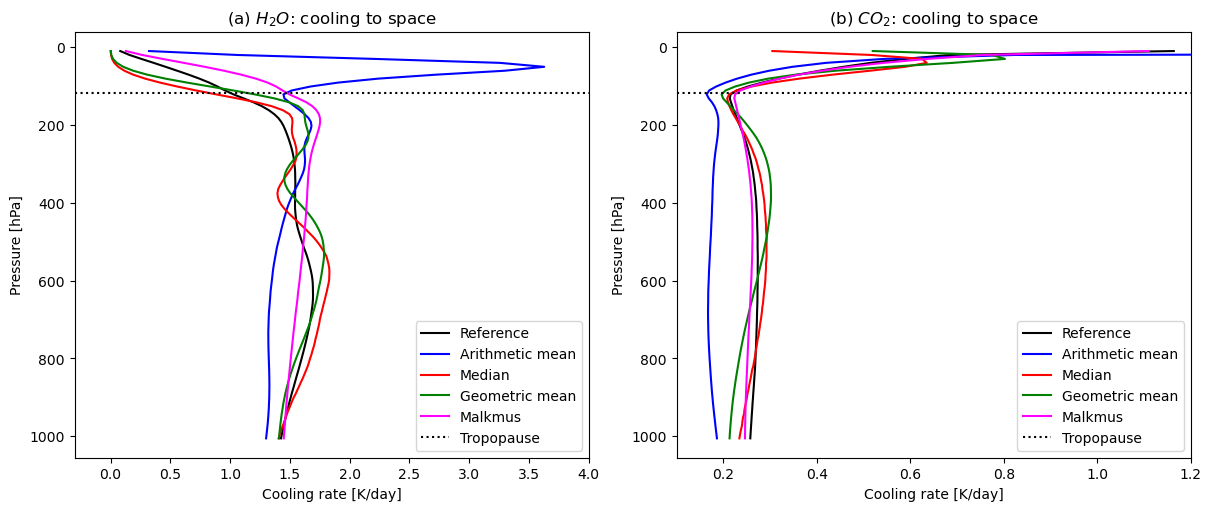

In [92]:
fig, ax = plt.subplots(1,2, squeeze=False, figsize=(12,5), constrained_layout = True)

T, T_half, q, q_half, p, p_half = atmosphere_4a()

nu_left_bound_i = 0
p_lower_bound_i = -2
p_upper_bound_i = 1
dp = p[51] - p[50]
ax[0,0].plot(cts_trans(p_half, q_half, T, trans_ref_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Reference", color = color_mean_trans)
ax[0,0].plot(cts_trans(p_half, q_half, T, trans_mean_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Arithmetic mean", color = color_mean_optical)
ax[0,0].plot(cts_trans(p_half, q_half, T, trans_median_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Median", color = color_median_optical)
ax[0,0].plot(cts_trans(p_half, q_half, T, trans_geom_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Geometric mean", color = color_geom_optical)
ax[0,0].plot(cts_trans(p_half, q_half, T, trans_avg_malkmus_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Malkmus", color = color_malkmus)


ax[0,0].hlines(p_tp/100, -0.3,4, color = 'black', linestyle = ':', label = 'Tropopause')

ax[0,0].set_ylabel('Pressure [hPa]')
ax[0,0].set_xlabel('Cooling rate [K/day]')
ax[0,0].set_xlim([-0.3, 4.0])
ax[0,0].legend(loc='lower right')
ax[0,0].invert_yaxis()
ax[0,0].set_title(r"(a) $H_2O$: cooling to space")

ax[0,1].plot(cts_trans(p_half, q_half, T, trans_ref_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Reference", color = color_mean_trans)
ax[0,1].plot(cts_trans(p_half, q_half, T, trans_mean_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Arithmetic mean", color = color_mean_optical)
ax[0,1].plot(cts_trans(p_half, q_half, T, trans_median_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Median", color = color_median_optical)
ax[0,1].plot(cts_trans(p_half, q_half, T, trans_geom_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Geometric mean", color = color_geom_optical)
ax[0,1].plot(cts_trans(p_half, q_half, T, trans_avg_malkmus_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Malkmus", color = color_malkmus)

ax[0,1].hlines(p_tp/100, 0.1,1.2, color = 'black', linestyle = ':', label = 'Tropopause')

ax[0,1].set_xlim([0.1,1.2])

ax[0,1].set_ylabel('Pressure [hPa]')
ax[0,1].set_xlabel('Cooling rate [K/day]')
ax[0,1].legend(loc='lower right')
ax[0,1].invert_yaxis()
ax[0,1].set_title(r"(b) $CO_2$: cooling to space")

# plt.savefig("cts_median_h2oco2.pdf")

## OLR

(-0.00023915732800763019, 0.005026125117119864)

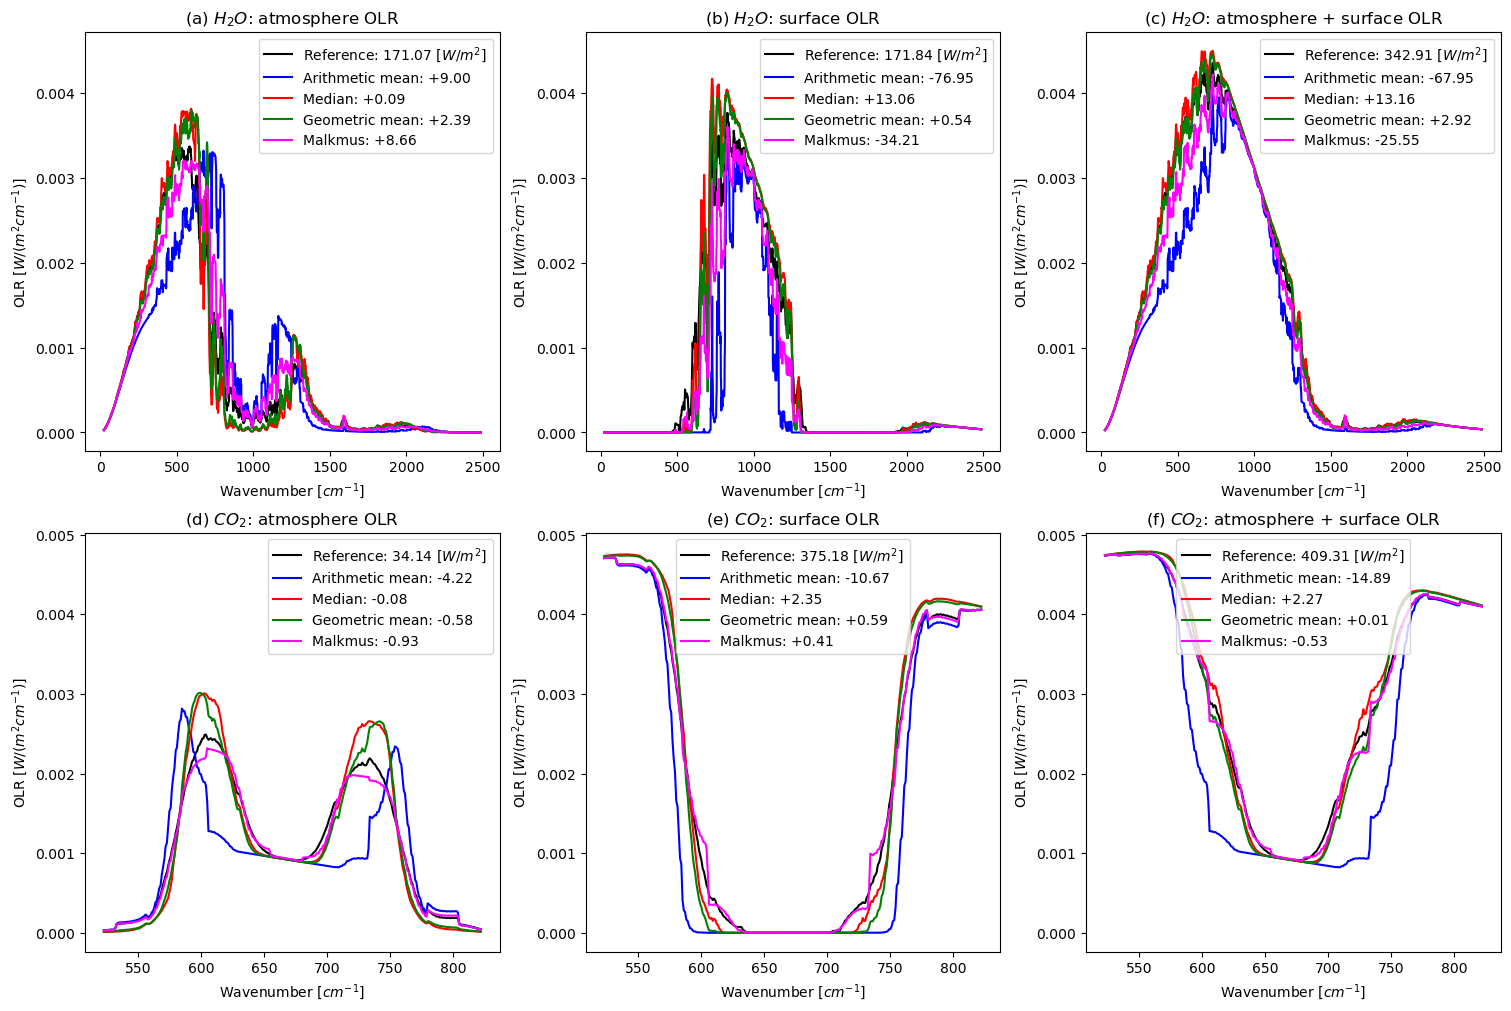

In [106]:
fig, ax = plt.subplots(2,3, squeeze=False, figsize=(15,10), constrained_layout = True)

T, T_half, q, q_half, p, p_half = atmosphere_4a()
qco2 = 400e-6
# T, T_half, q, q_half, p, p_half  = T[2:], T_half[2:], q[2:], q_half[2:], p[2:], p_half[2:]


olr_atm, olr_surf = olr_trans(p_half, q_half, T, T_half, trans_ref_h2o, nu_smooth*100)
olr_atm_avg, olr_surf_avg = olr_trans(p_half, q_half, T, T_half, trans_mean_h2o, nu_smooth*100)
olr_atm_median, olr_surf_median = olr_trans(p_half, q_half, T, T_half, trans_median_h2o, nu_smooth*100)
olr_atm_geom, olr_surf_geom = olr_trans(p_half, q_half, T, T_half, trans_geom_h2o, nu_smooth*100)
olr_atm_malkmus, olr_surf_malkmus = olr_trans(p_half, q_half, T, T_half, trans_avg_malkmus_h2o, nu_smooth*100)

delta_nu_smooth = (nu_smooth[1:] - nu_smooth[:-1]) * 100

olr_atm_tot = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu_smooth)
olr_surf_tot = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu_smooth)
olr_atm_avg_tot = np.sum((olr_atm_avg[1:] + olr_atm_avg[:-1])/2 * delta_nu_smooth)
olr_surf_avg_tot = np.sum((olr_surf_avg[1:] + olr_surf_avg[:-1])/2 * delta_nu_smooth)
olr_atm_median_tot = np.sum((olr_atm_median[1:] + olr_atm_median[:-1])/2 * delta_nu_smooth)
olr_surf_median_tot = np.sum((olr_surf_median[1:] + olr_surf_median[:-1])/2 * delta_nu_smooth)
olr_atm_geom_tot = np.sum((olr_atm_geom[1:] + olr_atm_geom[:-1])/2 * delta_nu_smooth)
olr_surf_geom_tot = np.sum((olr_surf_geom[1:] + olr_surf_geom[:-1])/2 * delta_nu_smooth)
olr_atm_malkmus_tot = np.sum((olr_atm_malkmus[1:] + olr_atm_malkmus[:-1])/2 * delta_nu_smooth)
olr_surf_malkmus_tot = np.sum((olr_surf_malkmus[1:] + olr_surf_malkmus[:-1])/2 * delta_nu_smooth)

y_lim_max = np.max((np.max(olr_atm + olr_surf), np.max((olr_atm_avg + olr_surf_avg, olr_atm_median + olr_surf_median))))
y_lim_min = np.min((np.min(olr_atm + olr_surf), np.min((olr_atm_avg + olr_surf_avg, olr_atm_median + olr_surf_median))))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05

ax[0,0].plot(nu_smooth, olr_atm, label = "Reference", color = color_mean_trans)
ax[0,0].plot(nu_smooth, olr_atm_avg, label = "Mean", color = color_mean_optical)
ax[0,0].plot(nu_smooth, olr_atm_median, label = "Median", color = color_median_optical)
ax[0,0].plot(nu_smooth, olr_atm_geom, label = "Median", color = color_geom_optical)
ax[0,0].plot(nu_smooth, olr_atm_malkmus, label = "Malkmus", color = color_malkmus)

ax[0,0].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,0].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[0,0].legend([rf"Reference: {olr_atm_tot:.2f} [$W/m^2$]",
                rf"Arithmetic mean: {olr_atm_avg_tot - olr_atm_tot:+.2f}",
                rf"Median: {olr_atm_median_tot - olr_atm_tot:+.2f}",
                rf"Geometric mean: {olr_atm_geom_tot - olr_atm_tot:+.2f}",
                rf"Malkmus: {olr_atm_malkmus_tot - olr_atm_tot:+.2f}"
               ],loc='upper right')
ax[0,0].set_title(r"(a) $H_2O$: atmosphere OLR")
ax[0,0].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[0,1].plot(nu_smooth, olr_surf, label = "Reference", color = color_mean_trans)
ax[0,1].plot(nu_smooth, olr_surf_avg, label = "Mean", color = color_mean_optical)
ax[0,1].plot(nu_smooth, olr_surf_median, label = "Median", color = color_median_optical)
ax[0,1].plot(nu_smooth, olr_surf_geom, label = "Median", color = color_geom_optical)
ax[0,1].plot(nu_smooth, olr_surf_malkmus, label = "Malkmus", color = color_malkmus)

ax[0,1].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,1].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[0,1].legend([rf"Reference: {olr_surf_tot:.2f} [$W/m^2$]", 
                rf"Arithmetic mean: {olr_surf_avg_tot - olr_surf_tot:+.2f}", 
                rf"Median: {olr_surf_median_tot - olr_surf_tot:+.2f}",
                rf"Geometric mean: {olr_surf_geom_tot - olr_surf_tot:+.2f}",
                rf"Malkmus: {olr_surf_malkmus_tot - olr_surf_tot:+.2f}"
               ],loc='upper right')
ax[0,1].set_title(r"(b) $H_2O$: surface OLR")
ax[0,1].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[0,2].plot(nu_smooth, olr_surf + olr_atm, label = "Reference", color = color_mean_trans)
ax[0,2].plot(nu_smooth, olr_surf_avg + olr_atm_avg, label = "Mean", color = color_mean_optical)
ax[0,2].plot(nu_smooth, olr_surf_median + olr_atm_median, label = "Median", color = color_median_optical)
ax[0,2].plot(nu_smooth, olr_surf_geom + olr_atm_geom, label = "Median", color = color_geom_optical)
ax[0,2].plot(nu_smooth, olr_surf_malkmus + olr_atm_malkmus, label = "Malkmus", color = color_malkmus)

ax[0,2].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,2].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[0,2].set_title(r"(c) $H_2O$: atmosphere + surface OLR")
ax[0,2].legend([rf"Reference: {olr_surf_tot+olr_atm_tot:.2f} [$W/m^2$]", 
                rf"Arithmetic mean: {(olr_surf_avg_tot+olr_atm_avg_tot) - (olr_surf_tot+olr_atm_tot):+.2f}", 
                rf"Median: {(olr_surf_median_tot+olr_atm_median_tot) - (olr_surf_tot+olr_atm_tot):+.2f}",
                rf"Geometric mean: {(olr_surf_geom_tot+olr_atm_geom_tot) - (olr_surf_tot+olr_atm_tot):+.2f}",
                rf"Malkmus: {(olr_surf_malkmus_tot+olr_atm_malkmus_tot) - (olr_surf_tot+olr_atm_tot):+.2f}"
               ],loc='upper right')
ax[0,2].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)


nu_a = 500
nu_b = 800

olr_atm, olr_surf = olr_trans(p_half, q_half, T, T_half, trans_ref_co2, nu_smooth*100)
olr_atm_avg, olr_surf_avg = olr_trans(p_half, q_half, T, T_half, trans_mean_co2, nu_smooth*100)
olr_atm_median, olr_surf_median = olr_trans(p_half, q_half, T, T_half, trans_median_co2, nu_smooth*100)
olr_atm_geom, olr_surf_geom = olr_trans(p_half, q_half, T, T_half, trans_geom_co2, nu_smooth*100)
olr_atm_malkmus, olr_surf_malkmus = olr_trans(p_half, q_half, T, T_half, trans_avg_malkmus_co2, nu_smooth*100)

delta_nu_smooth = (nu_smooth[1:] - nu_smooth[:-1]) * 100

olr_atm_tot = np.sum((olr_atm[1:] + olr_atm[:-1])/2 * delta_nu_smooth)
olr_surf_tot = np.sum((olr_surf[1:] + olr_surf[:-1])/2 * delta_nu_smooth)
olr_atm_avg_tot = np.sum((olr_atm_avg[1:] + olr_atm_avg[:-1])/2 * delta_nu_smooth)
olr_surf_avg_tot = np.sum((olr_surf_avg[1:] + olr_surf_avg[:-1])/2 * delta_nu_smooth)
olr_atm_median_tot = np.sum((olr_atm_median[1:] + olr_atm_median[:-1])/2 * delta_nu_smooth)
olr_surf_median_tot = np.sum((olr_surf_median[1:] + olr_surf_median[:-1])/2 * delta_nu_smooth)
olr_atm_geom_tot = np.sum((olr_atm_geom[1:] + olr_atm_geom[:-1])/2 * delta_nu_smooth)
olr_surf_geom_tot = np.sum((olr_surf_geom[1:] + olr_surf_geom[:-1])/2 * delta_nu_smooth)
olr_atm_malkmus_tot = np.sum((olr_atm_malkmus[1:] + olr_atm_malkmus[:-1])/2 * delta_nu_smooth)
olr_surf_malkmus_tot = np.sum((olr_surf_malkmus[1:] + olr_surf_malkmus[:-1])/2 * delta_nu_smooth)


y_lim_max = np.max((np.max(olr_atm + olr_surf), np.max((olr_atm_avg + olr_surf_avg, olr_atm_median + olr_surf_median))))
y_lim_min = np.min((np.min(olr_atm + olr_surf), np.min((olr_atm_avg + olr_surf_avg, olr_atm_median + olr_surf_median))))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05

ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm[nu_a:nu_b], label = "Reference", color = color_mean_trans)
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_avg[nu_a:nu_b], label = "Mean", color = color_mean_optical)
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_median[nu_a:nu_b], label = "Median", color = color_median_optical)
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_geom[nu_a:nu_b], label = "Median", color = color_geom_optical)
ax[1,0].plot(nu_smooth[nu_a:nu_b], olr_atm_malkmus[nu_a:nu_b], label = "Malkmus", color = color_malkmus)

ax[1,0].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,0].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[1,0].legend([rf"Reference: {olr_atm_tot:.2f} [$W/m^2$]",
                rf"Arithmetic mean: {olr_atm_avg_tot - olr_atm_tot:+.2f}",
                rf"Median: {olr_atm_median_tot - olr_atm_tot:+.2f}",
                rf"Geometric mean: {olr_atm_geom_tot - olr_atm_tot:+.2f}",
                rf"Malkmus: {olr_atm_malkmus_tot - olr_atm_tot:+.2f}"
               ],loc='upper right')
ax[1,0].set_title(r"(d) $CO_2$: atmosphere OLR")
ax[1,0].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf[nu_a:nu_b], label = "Reference", color = color_mean_trans)
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_avg[nu_a:nu_b], label = "Mean", color = color_mean_optical)
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_median[nu_a:nu_b], label = "Median", color = color_median_optical)
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_geom[nu_a:nu_b], label = "Median", color = color_geom_optical)
ax[1,1].plot(nu_smooth[nu_a:nu_b], olr_surf_malkmus[nu_a:nu_b], label = "Malkmus", color = color_malkmus)

ax[1,1].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,1].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[1,1].legend([rf"Reference: {olr_surf_tot:.2f} [$W/m^2$]", 
                rf"Arithmetic mean: {olr_surf_avg_tot - olr_surf_tot:+.2f}", 
                rf"Median: {olr_surf_median_tot - olr_surf_tot:+.2f}",
                rf"Geometric mean: {olr_surf_geom_tot - olr_surf_tot:+.2f}",
                rf"Malkmus: {olr_surf_malkmus_tot - olr_surf_tot:+.2f}"
               ],loc='upper center')
ax[1,1].set_title(r"(e) $CO_2$: surface OLR")
ax[1,1].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf[nu_a:nu_b] + olr_atm[nu_a:nu_b], label = "Reference", color = color_mean_trans)
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_avg[nu_a:nu_b] + olr_atm_avg[nu_a:nu_b], label = "Mean", color = color_mean_optical)
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_median[nu_a:nu_b] + olr_atm_median[nu_a:nu_b], label = "Median", color = color_median_optical)
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_geom[nu_a:nu_b] + olr_atm_geom[nu_a:nu_b], label = "Median", color = color_geom_optical)
ax[1,2].plot(nu_smooth[nu_a:nu_b], olr_surf_malkmus[nu_a:nu_b] + olr_atm_malkmus[nu_a:nu_b], label = "Malkmus", color = color_malkmus)

ax[1,2].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,2].set_ylabel(r'OLR [$W/(m^2 cm^{-1})$]')
ax[1,2].set_title(r"(f) $CO_2$: atmosphere + surface OLR")


ax[1,2].legend([rf"Reference: {olr_surf_tot+olr_atm_tot:.2f} [$W/m^2$]", 
                rf"Arithmetic mean: {(olr_surf_avg_tot+olr_atm_avg_tot) - (olr_surf_tot+olr_atm_tot):+.2f}", 
                rf"Median: {(olr_surf_median_tot+olr_atm_median_tot) - (olr_surf_tot+olr_atm_tot):+.2f}",
                rf"Geometric mean: {(olr_surf_geom_tot+olr_atm_geom_tot) - (olr_surf_tot+olr_atm_tot):+.2f}",
                rf"Malkmus: {(olr_surf_malkmus_tot+olr_atm_malkmus_tot) - (olr_surf_tot+olr_atm_tot):+.2f}"
               ],loc='upper center')
ax[1,2].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

# plt.savefig("OLR_median_h2oco2.pdf")

## Parameters of idealized model at each pressure level

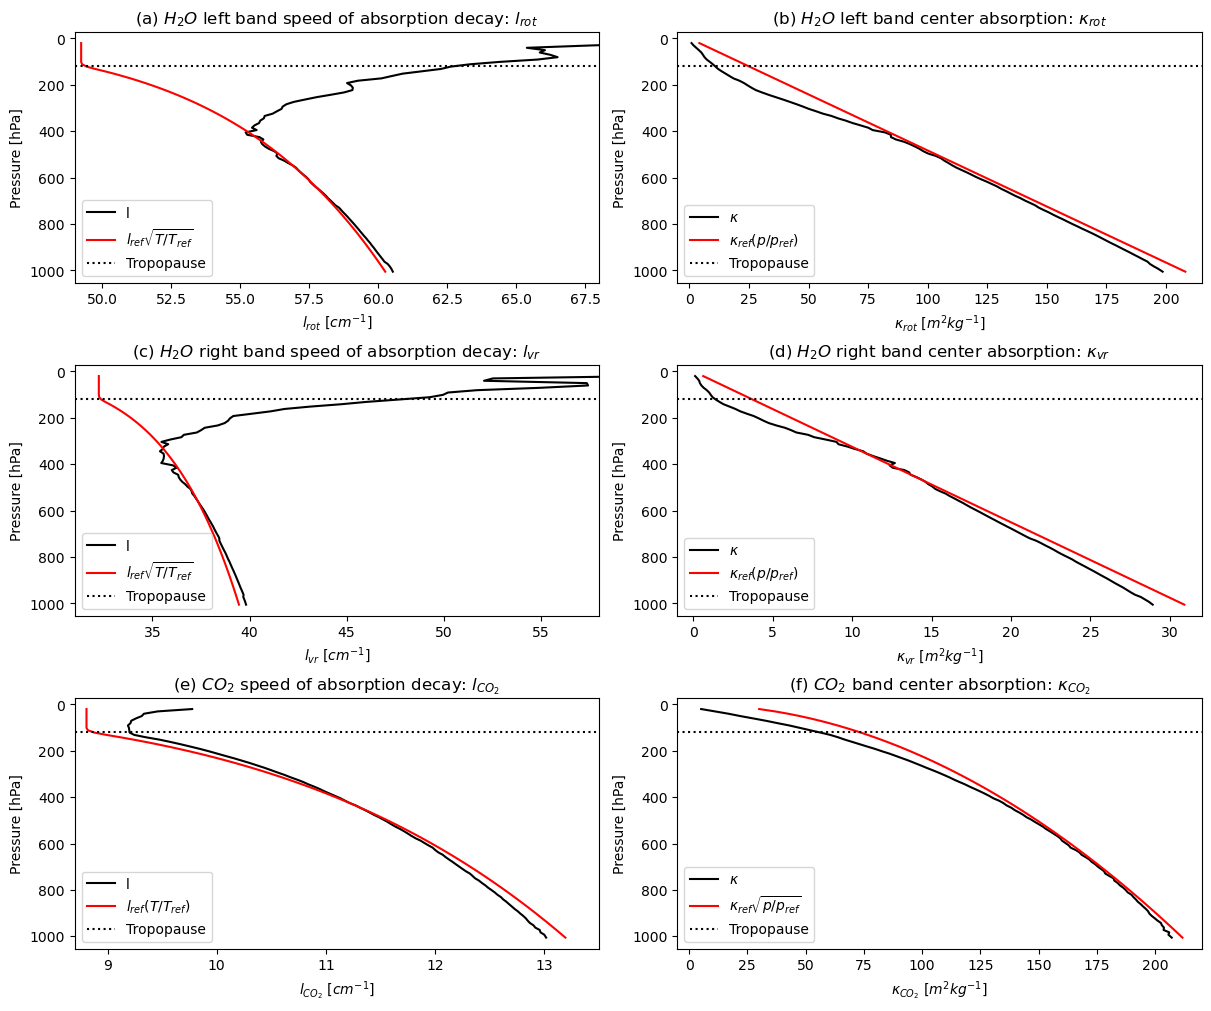

In [94]:
fig, ax = plt.subplots(3,2, squeeze=False, figsize=(12,10), constrained_layout = True)

T, T_half, q, q_half, p, p_half = atmosphere_4a()


ax[0,0].plot(l_rot_p, p[1:]/100, color = 'black', label = "l")
ax[0,0].plot(l_rot_p[50] * (np.sqrt(T[1:]/T[50])), p[1:]/100, color = 'red', label = r"$l_{ref} \sqrt{T/T_{ref}}$")
ax[0,0].hlines(p_tp/100, 49,68, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0,0].set_xlim([49,68])

ax[0,1].plot(kappa_rot_p, p[1:]/100, color = 'black', label = r"$\kappa$")
ax[0,1].plot((p[1:]/p[50])*kappa_rot_p[50], p[1:]/100, color = 'red', label = r"$\kappa_{ref}(p/p_{ref})$")
ax[0,1].hlines(p_tp/100, -5,215, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0,1].set_xlim([-5,215])


ax[0,0].set_title(r"(a) $H_2O$ left band speed of absorption decay: $l_{rot}$")
ax[0,0].set_ylabel('Pressure [hPa]')
ax[0,0].set_xlabel(r"$l_{rot}$ [$cm^{-1}$]")
ax[0,0].legend(loc='lower left')
ax[0,0].invert_yaxis()

ax[0,1].set_title(r"(b) $H_2O$ left band center absorption: $\kappa_{rot}$")
ax[0,1].set_ylabel('Pressure [hPa]')
ax[0,1].set_xlabel(r"$\kappa_{rot}$ [$m^2 kg^{-1}$]")
ax[0,1].legend(loc='lower left')
ax[0,1].invert_yaxis()


ax[1,0].plot(l_vr_p, p[1:]/100, color = 'black', label = "l")
ax[1,0].plot(l_vr_p[50] * np.sqrt(T[1:]/T[50]), p[1:]/100, color = 'red', label = r"$l_{ref} \sqrt{T/T_{ref}}$")
ax[1,0].hlines(p_tp/100,31,58, color = 'black', linestyle = ':', label = 'Tropopause')
ax[1,0].set_xlim([31,58])

ax[1,1].plot(kappa_vr_p, p[1:]/100, color = 'black', label = r"$\kappa$")
ax[1,1].plot((p[1:]/p[50])*kappa_vr_p[50], p[1:]/100, color = 'red', label = r"$\kappa_{ref}(p/p_{ref})$")
ax[1,1].hlines(p_tp/100,-1,32, color = 'black', linestyle = ':', label = 'Tropopause')
ax[1,1].set_xlim([-1,32])

ax[1,0].set_title(r"(c) $H_2O$ right band speed of absorption decay: $l_{vr}$")
ax[1,0].set_ylabel('Pressure [hPa]')
ax[1,0].set_xlabel(r"$l_{vr}$ [$cm^{-1}$]")
ax[1,0].legend(loc='lower left')
ax[1,0].invert_yaxis()

ax[1,1].set_title(r"(d) $H_2O$ right band center absorption: $\kappa_{vr}$")
ax[1,1].set_ylabel('Pressure [hPa]')
ax[1,1].set_xlabel(r"$\kappa_{vr}$ [$m^2 kg^{-1}$]")
ax[1,1].legend(loc='lower left')
ax[1,1].invert_yaxis()


ax[2,0].plot(l_co2_p_pm100, p[1:]/100, color = 'black', label = "l")
ax[2,0].plot(l_co2_p_pm100[50] * (T[1:]/T[50]), p[1:]/100, color = 'red', label = r"$l_{ref} (T/T_{ref})$")
ax[2,0].hlines(p_tp/100,8.7,13.5, color = 'black', linestyle = ':', label = 'Tropopause')
ax[2,0].set_xlim([8.7,13.5])


ax[2,1].plot(kappa_co2_p_pm100, p[1:]/100, color = 'black', label = r"$\kappa$")
ax[2,1].plot(np.sqrt(p[1:]/p[50])*kappa_co2_p_pm100[50], p[1:]/100, color = 'red', label = r"$\kappa_{ref}\sqrt{p/p_{ref}}$")
ax[2,1].hlines(p_tp/100,-5,220, color = 'black', linestyle = ':', label = 'Tropopause')
ax[2,1].set_xlim([-5,220])


ax[2,0].set_title(r"(e) $CO_2$ speed of absorption decay: $l_{CO_2}$")
ax[2,0].set_ylabel('Pressure [hPa]')
ax[2,0].set_xlabel(r"$l_{CO_2}$ [$cm^{-1}$]")
ax[2,0].legend(loc='lower left')
ax[2,0].invert_yaxis()

ax[2,1].set_title(r"(f) $CO_2$ band center absorption: $\kappa_{CO_2}$")
ax[2,1].set_ylabel('Pressure [hPa]')
ax[2,1].set_xlabel(r"$\kappa_{CO_2}$ [$m^2 kg^{-1}$]")
ax[2,1].legend(loc='lower left')
ax[2,1].invert_yaxis()

# plt.savefig(f"l_kappa_h2oco2.pdf")

## CTS with idealized model

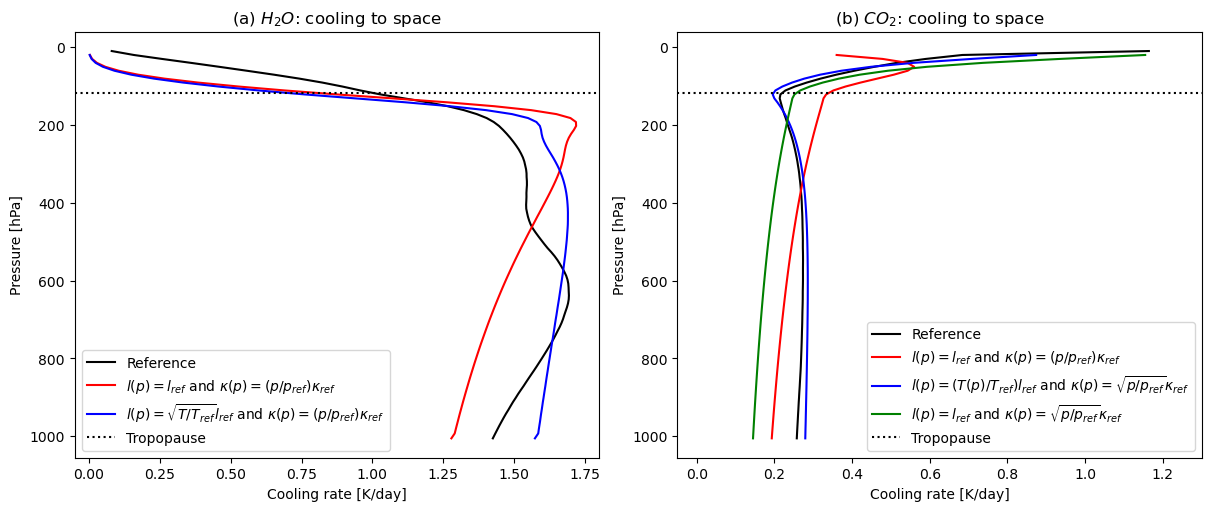

In [95]:
fig, ax = plt.subplots(1,2, squeeze=False, figsize=(12,5), constrained_layout = True)

T, T_half, q, q_half, p, p_half = atmosphere_4a()
qco2 = 400e-6


nu_left_bound_i = 0
p_lower_bound_i = -2
dp = p[51] - p[50]

ax[0,0].plot(cts_trans(p_half, q_half, T, trans_ref_h2o, nu_smooth*100) * 3600 * 24, p/100, label = "Reference", color = color_mean_trans)
ax[0,0].plot(cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_h2o, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) = l_{ref}$ and $\kappa(p) = (p/p_{ref})\kappa_{ref}$", color = 'red', linestyle = "-")
ax[0,0].plot(cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_fit_h2o, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) = \sqrt{T/T_{ref}} l_{ref}$ and $\kappa(p) = (p/p_{ref})\kappa_{ref}$", color = 'blue', linestyle = "-")


# ax[0,0].plot(CTS_lbl_h2o[:-1] * 3600 * 24, p[:-2]/100, label = "Reference", color = 'black')

ax[0,0].hlines(p_tp/100, -0.05, 1.8, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0,0].set_xlim([-0.05, 1.8])

ax[0,0].set_ylabel('Pressure [hPa]')
ax[0,0].set_xlabel('Cooling rate [K/day]')
ax[0,0].set_title(r"(a) $H_2 O$: cooling to space")
ax[0,0].legend(loc='lower left')
ax[0,0].invert_yaxis()

nu_left_bound_i = 0
p_lower_bound_i = -2
dp = p[51] - p[50]

ax[0,1].plot(cts_trans(p_half, q_half, T, trans_ref_co2, nu_smooth*100) * 3600 * 24, p/100, label = "Reference", color = color_mean_trans)
ax[0,1].plot(cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_co2, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) = l_{ref}$ and $\kappa(p) = (p/p_{ref})\kappa_{ref}$", color = 'red', linestyle = "-")
ax[0,1].plot(cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_fit_co2, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) =(T(p)/T_{ref}) l_{ref}$ and $\kappa(p)=\sqrt{p/p_{ref}}\kappa_{ref}$", color = 'blue', linestyle = "-")
ax[0,1].plot(cts_trans(p_half[1:], q_half[1:], T[1:], trans_idealized_fit_onlykappa_co2, nu_smooth*100) * 3600 * 24, p[1:]/100, label = r"$l(p) = l_{ref}$ and $\kappa(p)=\sqrt{p/p_{ref}}\kappa_{ref}$", color = 'green', linestyle = "-")

ax[0,1].hlines(p_tp/100, -0.05, 1.3, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0,1].set_xlim([-0.05, 1.3])


ax[0,1].set_ylabel('Pressure [hPa]')
ax[0,1].set_xlabel('Cooling rate [K/day]')
ax[0,1].set_title(r"(b) $CO_2$: cooling to space")
ax[0,1].legend(loc='lower right')
ax[0,1].invert_yaxis()
# plt.savefig("cts_idealized_models_h2oco2.pdf")

## OLR with idealized model

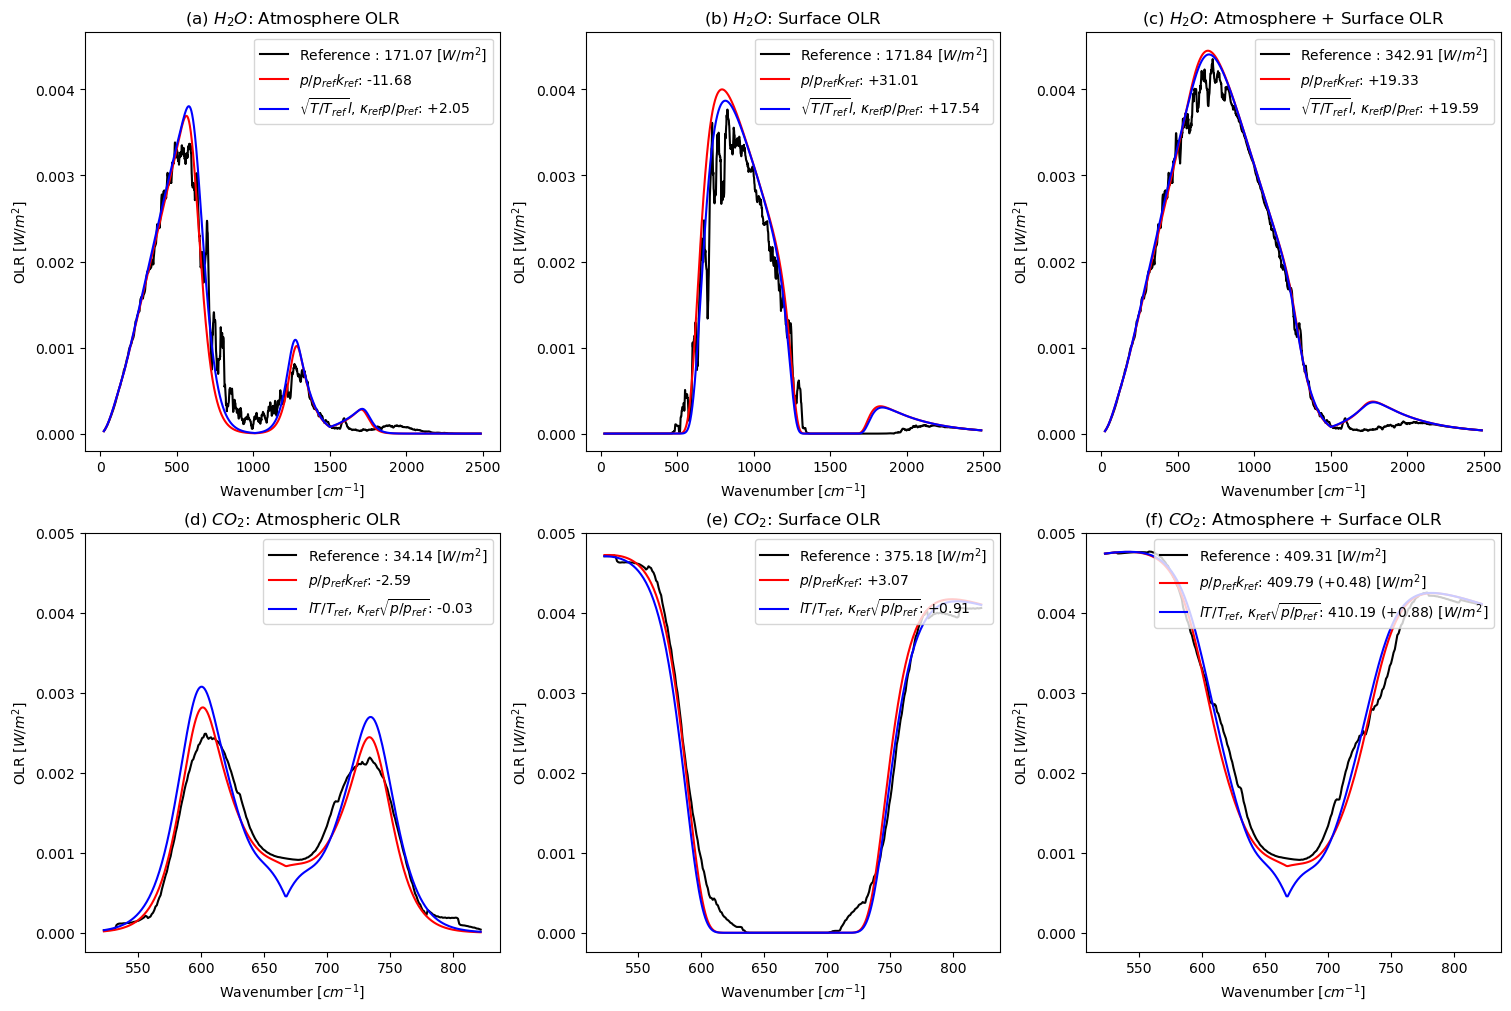

In [96]:
fig, ax = plt.subplots(2,3, squeeze=False, figsize=(15,10), constrained_layout = True)

T, T_half, q, q_half, p, p_half = atmosphere_4a()
qco2 = 400e-6
# T, T_half, q, q_half, p, p_half  = T[2:], T_half[2:], q[2:], q_half[2:], p[2:], p_half[2:]


HR_nu, HR_surf = olr_trans(p_half, q_half, T, T_half, trans_ref_h2o, nu_smooth*100)
HR_nu_avg, HR_surf_avg = olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_p_h2o, nu_smooth*100)
HR_nu_median, HR_surf_median = olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_h2o, nu_smooth*100)
HR_nu_avg_malkmus, HR_surf_avg_malkmus = olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_fit_h2o, nu_smooth*100)


delta_nu_smooth = (nu_smooth[1:] - nu_smooth[:-1]) * 100

HR_nu_tot = np.sum((HR_nu[1:] + HR_nu[:-1])/2 * delta_nu_smooth)
HR_surf_tot = np.sum((HR_surf[1:] + HR_surf[:-1])/2 * delta_nu_smooth)
HR_nu_avg_tot = np.sum((HR_nu_avg[1:] + HR_nu_avg[:-1])/2 * delta_nu_smooth)
HR_surf_avg_tot = np.sum((HR_surf_avg[1:] + HR_surf_avg[:-1])/2 * delta_nu_smooth)
HR_nu_median_tot = np.sum((HR_nu_median[1:] + HR_nu_median[:-1])/2 * delta_nu_smooth)
HR_surf_median_tot = np.sum((HR_surf_median[1:] + HR_surf_median[:-1])/2 * delta_nu_smooth)
HR_nu_avg_malkmus_tot = np.sum((HR_nu_avg_malkmus[1:] + HR_nu_avg_malkmus[:-1])/2 * delta_nu_smooth)
HR_surf_avg_malkmus_tot = np.sum((HR_surf_avg_malkmus[1:] + HR_surf_avg_malkmus[:-1])/2 * delta_nu_smooth)

y_lim_max = np.max((np.max(HR_nu + HR_surf), np.max((HR_nu_avg + HR_surf_avg, HR_nu_median + HR_surf_median, HR_nu_avg_malkmus + HR_surf_avg_malkmus))))
y_lim_min = np.min((np.min(HR_nu + HR_surf), np.min((HR_nu_avg + HR_surf_avg, HR_nu_median + HR_surf_median, HR_nu_avg_malkmus + HR_surf_avg_malkmus))))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05

ax[0,0].plot(nu_smooth, HR_nu, label = f"Reference : {HR_nu_tot:.2f} [$W/m^2$]", color = 'black')
ax[0,0].plot(nu_smooth, HR_nu_median, label = rf"$p/p_{{ref}} k_{{ref}}$: {HR_nu_median_tot - HR_nu_tot:+.2f}", color = 'red')
ax[0,0].plot(nu_smooth, HR_nu_avg_malkmus, label = rf"$\sqrt{{T/T_{{ref}}}}l $, $\kappa_{{ref}} p/p_{{ref}}$: {HR_nu_avg_malkmus_tot - HR_nu_tot:+.2f}", color = 'blue')


ax[0,0].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,0].set_ylabel(r'OLR [$W/m^2$]')
ax[0,0].legend(loc="upper right")
ax[0,0].set_title(r"(a) $H_2 O$: Atmosphere OLR")
ax[0,0].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[0,1].plot(nu_smooth, HR_surf, label = f"Reference : {HR_surf_tot:.2f} [$W/m^2$]", color = 'black')
ax[0,1].plot(nu_smooth, HR_surf_median, label = rf"$p/p_{{ref}} k_{{ref}}$: {HR_surf_median_tot - HR_surf_tot:+.2f}", color = 'red')
ax[0,1].plot(nu_smooth, HR_surf_avg_malkmus, label = rf"$\sqrt{{T/T_{{ref}}}}l $, $\kappa_{{ref}} p/p_{{ref}}$: {HR_surf_avg_malkmus_tot - HR_surf_tot:+.2f}", color = 'blue')


ax[0,1].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,1].set_ylabel(r'OLR [$W/m^2$]')
ax[0,1].legend(loc="upper right")
ax[0,1].set_title(r"(b) $H_2 O$: Surface OLR")
ax[0,1].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[0,2].plot(nu_smooth, HR_surf + HR_nu, label = f"Reference : {HR_surf_tot+HR_nu_tot:.2f} [$W/m^2$]", color = 'black')
ax[0,2].plot(nu_smooth, HR_surf_median + HR_nu_median, label = rf"$p/p_{{ref}} k_{{ref}}$: {(HR_surf_median_tot+HR_nu_median_tot) - (HR_surf_tot+HR_nu_tot):+.2f}", color = 'red')
ax[0,2].plot(nu_smooth, HR_surf_avg_malkmus + HR_nu_avg_malkmus, label = rf"$\sqrt{{T/T_{{ref}}}}l $, $\kappa_{{ref}} p/p_{{ref}}$: {(HR_surf_avg_malkmus_tot + HR_nu_avg_malkmus_tot) - (HR_surf_tot+HR_nu_tot):+.2f}", color = 'blue')

ax[0,2].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[0,2].set_ylabel(r'OLR [$W/m^2$]')
ax[0,2].set_title(r"(c) $H_2 O$: Atmosphere + Surface OLR")
ax[0,2].legend(loc="upper right")
ax[0,2].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

nu_a = 500
nu_b = 800

HR_nu, HR_surf = olr_trans(p_half, q_half, T, T_half, trans_ref_co2, nu_smooth*100)
HR_nu_avg, HR_surf_avg = olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_p_co2, nu_smooth*100)
HR_nu_median, HR_surf_median = olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_co2, nu_smooth*100)
HR_nu_avg_malkmus, HR_surf_avg_malkmus = olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_fit_co2, nu_smooth*100)
HR_nu_fit, HR_surf_fit = olr_trans(p_half[1:], q_half[1:], T[1:], T_half[1:], trans_idealized_fit_onlykappa_co2, nu_smooth*100)

delta_nu_smooth = (nu_smooth[1:] - nu_smooth[:-1]) * 100

HR_nu_tot = np.sum((HR_nu[1:] + HR_nu[:-1])/2 * delta_nu_smooth)
HR_surf_tot = np.sum((HR_surf[1:] + HR_surf[:-1])/2 * delta_nu_smooth)
HR_nu_avg_tot = np.sum((HR_nu_avg[1:] + HR_nu_avg[:-1])/2 * delta_nu_smooth)
HR_surf_avg_tot = np.sum((HR_surf_avg[1:] + HR_surf_avg[:-1])/2 * delta_nu_smooth)
HR_nu_median_tot = np.sum((HR_nu_median[1:] + HR_nu_median[:-1])/2 * delta_nu_smooth)
HR_surf_median_tot = np.sum((HR_surf_median[1:] + HR_surf_median[:-1])/2 * delta_nu_smooth)
HR_nu_avg_malkmus_tot = np.sum((HR_nu_avg_malkmus[1:] + HR_nu_avg_malkmus[:-1])/2 * delta_nu_smooth)
HR_surf_avg_malkmus_tot = np.sum((HR_surf_avg_malkmus[1:] + HR_surf_avg_malkmus[:-1])/2 * delta_nu_smooth)
HR_nu_fit_tot = np.sum((HR_nu_fit[1:] + HR_nu_fit[:-1])/2 * delta_nu_smooth)
HR_surf_fit_tot = np.sum((HR_surf_fit[1:] + HR_surf_fit[:-1])/2 * delta_nu_smooth)

y_lim_max = np.max((np.max(HR_nu + HR_surf), np.max((HR_nu_avg + HR_surf_avg, HR_nu_median + HR_surf_median, HR_nu_avg_malkmus + HR_surf_avg_malkmus))))
y_lim_min = np.min((np.min(HR_nu + HR_surf), np.min((HR_nu_avg + HR_surf_avg, HR_nu_median + HR_surf_median, HR_nu_avg_malkmus + HR_surf_avg_malkmus))))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05

ax[1,0].plot(nu_smooth[nu_a:nu_b], HR_nu[nu_a:nu_b], label = f"Reference : {HR_nu_tot:.2f} [$W/m^2$]", color = 'black')
ax[1,0].plot(nu_smooth[nu_a:nu_b], HR_nu_median[nu_a:nu_b], label = rf"$p/p_{{ref}} k_{{ref}}$: {HR_nu_median_tot - HR_nu_tot:+.2f}", color = 'red')
ax[1,0].plot(nu_smooth[nu_a:nu_b], HR_nu_avg_malkmus[nu_a:nu_b], label = rf"$l T/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {HR_nu_avg_malkmus_tot - HR_nu_tot:+.2f}", color = 'blue')


ax[1,0].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,0].set_ylabel(r'OLR [$W/m^2$]')
ax[1,0].legend(loc="upper right")
ax[1,0].set_title(r"(d) $CO_2$: Atmospheric OLR")
ax[1,0].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

ax[1,1].plot(nu_smooth[nu_a:nu_b], HR_surf[nu_a:nu_b], label = f"Reference : {HR_surf_tot:.2f} [$W/m^2$]", color = 'black')
ax[1,1].plot(nu_smooth[nu_a:nu_b], HR_surf_median[nu_a:nu_b], label = rf"$p/p_{{ref}} k_{{ref}}$: {HR_surf_median_tot - HR_surf_tot:+.2f}", color = 'red')
ax[1,1].plot(nu_smooth[nu_a:nu_b], HR_surf_avg_malkmus[nu_a:nu_b], label = rf"$lT/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {HR_surf_avg_malkmus_tot - HR_surf_tot:+.2f}", color = 'blue')

ax[1,1].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,1].set_ylabel(r'OLR [$W/m^2$]')
ax[1,1].legend([f"Reference : {HR_surf_tot:.2f} [$W/m^2$]", 
                rf"$p/p_{{ref}} k_{{ref}}$: {HR_surf_median_tot - HR_surf_tot:+.2f}", 
                rf"$lT/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {HR_surf_avg_malkmus_tot - HR_surf_tot:+.2f}",
               ],loc='upper right')
ax[1,1].set_title(r"(e) $CO_2$: Surface OLR")
ax[1,1].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)
ax[1,1].legend(loc="upper right")


ax[1,2].plot(nu_smooth[nu_a:nu_b], HR_surf[nu_a:nu_b] + HR_nu[nu_a:nu_b], label = f"Reference : {HR_surf_tot+HR_nu_tot:.2f} [$W/m^2$]", color = 'black')
ax[1,2].plot(nu_smooth[nu_a:nu_b], HR_surf_median[nu_a:nu_b] + HR_nu_median[nu_a:nu_b], label = rf"$p/p_{{ref}} k_{{ref}}$: {HR_surf_median_tot+HR_nu_median_tot:.2f} ({(HR_surf_median_tot+HR_nu_median_tot) - (HR_surf_tot+HR_nu_tot):+.2f}) [$W/m^2$]", color = 'red')
ax[1,2].plot(nu_smooth[nu_a:nu_b], HR_surf_avg_malkmus[nu_a:nu_b] + HR_nu_avg_malkmus[nu_a:nu_b], label = rf"$lT/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {HR_surf_avg_malkmus_tot + HR_nu_avg_malkmus_tot:.2f} ({(HR_surf_avg_malkmus_tot + HR_nu_avg_malkmus_tot) - (HR_surf_tot+HR_nu_tot):+.2f}) [$W/m^2$]", color = 'blue')

ax[1,2].set_xlabel(r'Wavenumber [$cm^{-1}$]')
ax[1,2].set_ylabel(r'OLR [$W/m^2$]')
ax[1,2].set_title(r"(f) $CO_2$: Atmosphere + Surface OLR")
ax[1,2].legend([f"Reference : {HR_surf_tot+HR_nu_tot:.2f} [$W/m^2$]", 
                rf"$p/p_{{ref}} k_{{ref}}$: {(HR_surf_median_tot+HR_nu_median_tot) - (HR_surf_tot+HR_nu_tot):+.2f}", 
                rf"$lT/T_{{ref}} $, $\kappa_{{ref}} \sqrt{{p/p_{{ref}}}}$: {(HR_surf_avg_malkmus_tot + HR_nu_avg_malkmus_tot) - (HR_surf_tot+HR_nu_tot):+.2f}",
               ],loc='upper right')
ax[1,2].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)
ax[1,2].legend(loc="upper right")

# plt.savefig("OLR_idealized_h2oco2.pdf")

# Figures with H2O and CO2

In [260]:
T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

Text(0, 0.5, 'Pressure [hPa]')

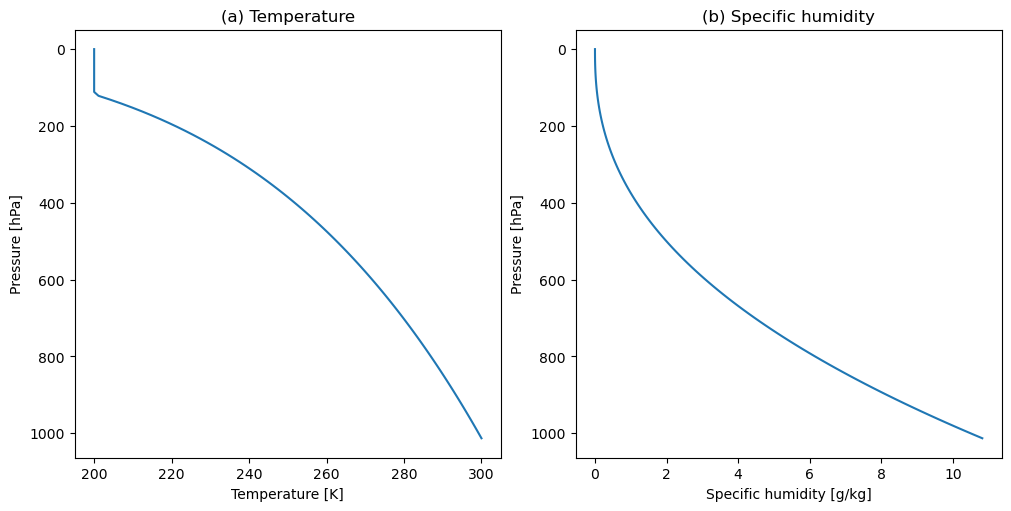

In [261]:
fig, ax = plt.subplots(1,2, squeeze=False, figsize=(10,5), constrained_layout = True)

ax[0,0].plot(T_half, p_half/100)
ax[0,0].invert_yaxis()
ax[0,0].set_title('(a) Temperature')
ax[0,0].set_xlabel('Temperature [K]')
ax[0,0].set_ylabel('Pressure [hPa]')

ax[0,1].plot(q_half * 1000, p_half/100)
ax[0,1].invert_yaxis()
ax[0,1].set_title('(b) Specific humidity')
ax[0,1].set_xlabel('Specific humidity [g/kg]')
ax[0,1].set_ylabel('Pressure [hPa]')
# plt.savefig('idealized_atmosphere.pdf')

## CTS

In [262]:
T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
p_tp = tropopause(ps = 100000, Ts = 300)
qco2 = 400e-6

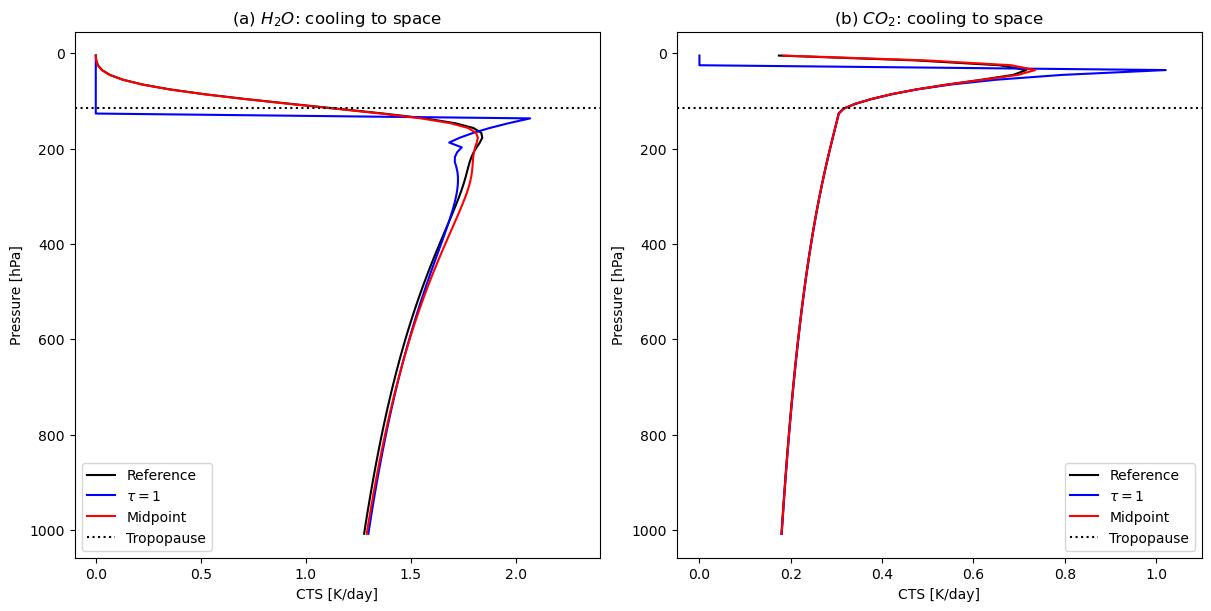

In [294]:
T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

fig, ax = plt.subplots(1,2, figsize=(12,6), constrained_layout = True)

HR_tau1 = cts_tau1_h2o(p,p_half,q, q_half,T,T_half)
HR_transmid = cts_transmid_h2o(p,p_half,q, q_half,T,T_half)
HR_ref = cts_h2o(p_half, q_half, T)

ax[0].plot(HR_ref.sum(axis=0) * 3600 * 24,p/100, c = 'black', label = 'Reference', linestyle = '-')
ax[0].plot(HR_tau1.sum(axis=0) * 3600 * 24,p/100, c = 'blue', label = r'$\tau = 1$', linestyle = '-')
ax[0].plot(HR_transmid.sum(axis=0) * 3600 * 24,p/100, c = 'red', label = 'Midpoint', linestyle = '-')

ax[0].hlines(p_tp/100, -0.1, 2.4, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0].set_xlim([-0.1, 2.4])

ax[0].invert_yaxis()

ax[0].set_title(r'(a) $H_2 O$: cooling to space')
ax[0].set_xlabel('CTS [K/day]')
ax[0].set_ylabel('Pressure [hPa]')
ax[0].legend(loc = 'lower left')

qco2 = 400e-6
HR_tau1 = cts_tau1_co2(p,p_half,qco2,T,T_half)
HR_transmid = cts_transmid_co2(p,p_half,qco2,T,T_half)
HR_ref = cts_co2(p_half, qco2, T)

ax[1].plot(HR_ref.sum(axis=0) * 3600 * 24,p/100, c = 'black', label = 'Reference', linestyle = '-')
ax[1].plot(HR_tau1.sum(axis=0) * 3600 * 24,p/100, c = 'blue', label = r'$\tau = 1$', linestyle = '-')
ax[1].plot(HR_transmid.sum(axis=0) * 3600 * 24,p/100, c = 'red', label = 'Midpoint', linestyle = '-')

ax[1].hlines(p_tp/100, -0.05, 1.1, color = 'black', linestyle = ':', label = 'Tropopause')
ax[1].set_xlim([-0.05, 1.1])


ax[1].invert_yaxis()

ax[1].set_title(r'(b) $CO_2$: cooling to space')
ax[1].set_xlabel('CTS [K/day]')
ax[1].set_ylabel('Pressure [hPa]')
ax[1].legend(loc = 'lower right')

# plt.savefig('cts_tau1_transmid_h2oco2.pdf')


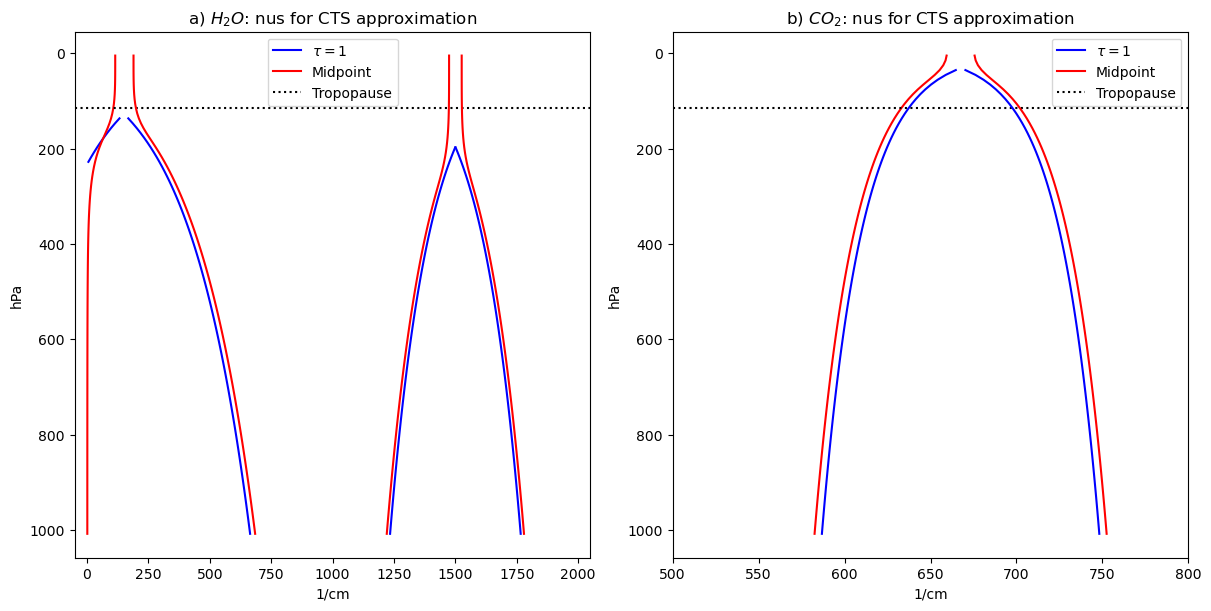

In [295]:
T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

fig, ax = plt.subplots(1,2, figsize=(12,6), constrained_layout = True)


pq = total_pq(p,q)
tau_rot_left_min = pq * k_h2o(nu_min)
tau_rot_right_min = pq * k_h2o(nu_mid)
tau_rot_max = pq * kappa_rot
tau_vr_left_min = pq * k_h2o(nu_mid)
tau_vr_right_min = pq * k_h2o(nu_max)
tau_vr_max = pq * kappa_vr
trans_nu = np.zeros((4,p.size))
trans_nu[0] = (np.exp(-tau_rot_left_min) + np.exp(-tau_rot_max))/2
trans_nu[1] = (np.exp(-tau_rot_right_min) + np.exp(-tau_rot_max))/2
trans_nu[2] = (np.exp(-tau_vr_left_min) + np.exp(-tau_vr_max))/2
trans_nu[3] = (np.exp(-tau_vr_right_min) + np.exp(-tau_vr_max))/2
nus_tau1_h2o = tau_inverse_h2o(pq, 1)
nus_transmid_h2o = trans_inverse_h2o(pq, trans_nu)
mask1_h2o = (nus_tau1_h2o[0] != -1)
mask2_h2o = (nus_tau1_h2o[1] != -1)
mask3_h2o = (nus_tau1_h2o[2] != -1)
mask4_h2o = (nus_tau1_h2o[3] != -1)

pq = total_pq(p,qco2 + np.zeros_like(p))
tau_co2_left_min = pq * k_co2(nu_min)
tau_co2_right_min = pq * k_co2(nu_max)
tau_co2_max = pq * kappa_co2
trans_nu = np.zeros((2,p.size))
trans_nu[0] = (np.exp(-tau_co2_left_min) + np.exp(-tau_co2_max))/2
trans_nu[1] = (np.exp(-tau_co2_right_min) + np.exp(-tau_co2_max))/2
nus_tau1_co2 = tau_inverse_co2(pq, 1)
nus_transmid_co2 = trans_inverse_co2(pq, trans_nu)
mask1_co2 = (nus_tau1_co2[0] != -1)
mask2_co2 = (nus_tau1_co2[1] != -1)



ax[0].plot(nus_tau1_h2o[0][mask1_h2o]/100,p[mask1_h2o]/100, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(nus_transmid_h2o[0]/100,p/100, c='red', label='Midpoint',linestyle = "-")
ax[0].hlines(p_tp/100, -50,2050, color = 'black', linestyle = ':', label = 'Tropopause')

ax[0].legend()
ax[0].set_xlim(-50,2050)

ax[0].plot(nus_tau1_h2o[1][mask2_h2o]/100,p[mask2_h2o]/100, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(nus_tau1_h2o[2][mask3_h2o]/100,p[mask3_h2o]/100, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(nus_tau1_h2o[3][mask4_h2o]/100,p[mask4_h2o]/100, c='blue', label=r'$\tau = 1$', linestyle = "-")

ax[0].plot(nus_transmid_h2o[1]/100,p/100, c='red', label='Midpoint',linestyle = "-")
ax[0].plot(nus_transmid_h2o[2]/100,p/100, c='red', label='Midpoint',linestyle = "-")
ax[0].plot(nus_transmid_h2o[3]/100,p/100, c='red', label='Midpoint',linestyle = "-")

ax[0].invert_yaxis()

ax[0].set_title(r'a) $H_2 O$: nus for CTS approximation')
ax[0].set_xlabel('1/cm')
ax[0].set_ylabel('hPa')


ax[1].plot(nus_tau1_co2[0][mask1_co2]/100,p[mask1_co2]/100, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1].plot(nus_transmid_co2[0]/100,p/100, c='red', label='Midpoint',linestyle = "-")
ax[1].hlines(p_tp/100, 500,800, color = 'black', linestyle = ':', label = 'Tropopause')

ax[1].legend()
ax[1].set_xlim(500,800)

ax[1].plot(nus_tau1_co2[1][mask2_co2]/100,p[mask2_co2]/100, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1].plot(nus_transmid_co2[1]/100,p/100, c='red', label='Midpoint',linestyle = "-")

ax[1].invert_yaxis()

ax[1].set_title(r'b) $CO_2$: nus for CTS approximation')
ax[1].set_xlabel('1/cm')
ax[1].set_ylabel('hPa')

# plt.savefig('nus_tau1_transmid_cts_h2oco2.pdf')

/tmp/ipykernel_25370/23733347.py:2: RuntimeWarning: divide by zero encountered in log
  nu1 = - l_rot * np.log(pq * kappa_rot) + nu_rot + l_rot * np.log(np.abs(np.log(trans[0])))


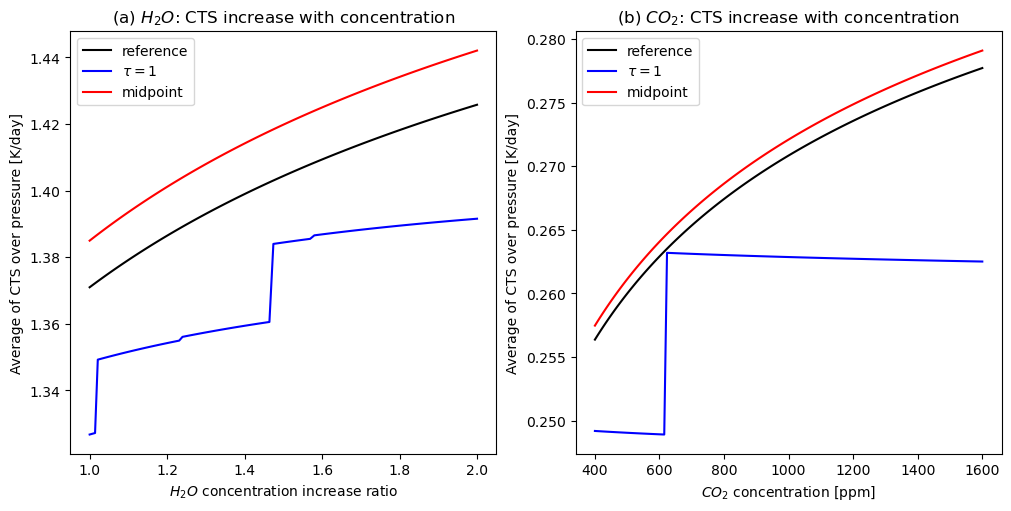

In [296]:
T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

mean_HR_nu_h2o = np.zeros(101)
mean_HR_nu_1_h2o = np.zeros(101)
mean_HR_nu_transavg_h2o = np.zeros(101)
ratio_increase  = np.array([1 * 2 **(n/100) for n in range(101)])
delta_p = p[1:] - p[:-1]
qco2 = 400e-6
for n in range(101):
    q_half2 = ratio_increase[n] * q_half
    q_2 = ratio_increase[n] * q
    
    HR_nu= cts_h2o(p_half, q_half2, T)
    HR_nu_1= cts_tau1_h2o(p,p_half,q_2, q_half2,T,T_half)
    HR_nu_transavg=  cts_transmid_h2o(p,p_half,q_2, q_half2,T,T_half)
    
    mean_HR_nu_h2o[n] = np.sum((HR_nu.sum(axis=0)[1:] + HR_nu.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24
    mean_HR_nu_1_h2o[n] = np.sum((HR_nu_1.sum(axis=0)[1:] + HR_nu_1.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24
    mean_HR_nu_transavg_h2o[n] = np.sum((HR_nu_transavg.sum(axis=0)[1:] + HR_nu_transavg.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24


mean_HR_nu_co2 = np.zeros(101)
mean_HR_nu_1_co2 = np.zeros(101)
mean_HR_nu_transavg_co2 = np.zeros(101)
ratio_increase  = np.array([1 * 2 **(n/100) for n in range(101)])
delta_p = p[1:] - p[:-1]
q_co2 = np.array([400e-6 * 2 **(n/50) for n in range(101)])
for n in range(101):
    qco2 = q_co2[n]
    
    HR_nu= cts_co2(p_half, qco2, T)
    HR_nu_1= cts_tau1_co2(p,p_half,qco2,T,T_half)
    HR_nu_transavg =  cts_transmid_co2(p,p_half,qco2,T,T_half)
    
    mean_HR_nu_co2[n] = np.sum((HR_nu.sum(axis=0)[1:] + HR_nu.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24
    mean_HR_nu_1_co2[n] = np.sum((HR_nu_1.sum(axis=0)[1:] + HR_nu_1.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24
    mean_HR_nu_transavg_co2[n] = np.sum((HR_nu_transavg.sum(axis=0)[1:] + HR_nu_transavg.sum(axis=0)[:-1])/2 * delta_p)/ps  * 3600 * 24



fig, ax = plt.subplots(1,2, figsize=(10,5), constrained_layout = True)

ax[0].plot(ratio_increase, mean_HR_nu_h2o, c='black', label='reference',linestyle = "-")
ax[0].plot(ratio_increase, mean_HR_nu_1_h2o, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(ratio_increase, mean_HR_nu_transavg_h2o, c='red', label='midpoint', linestyle = "-")
ax[0].legend()

ax[0].set_title(r"(a) $H_2 O$: CTS increase with concentration")
ax[0].set_xlabel(r"$H_2 O$ concentration increase ratio")
ax[0].set_ylabel(r'Average of CTS over pressure [K/day]')

ax[1].plot(q_co2 * 1e6, mean_HR_nu_co2, c='black', label='reference',linestyle = "-")
ax[1].plot(q_co2 * 1e6, mean_HR_nu_1_co2, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1].plot(q_co2 * 1e6, mean_HR_nu_transavg_co2, c='red', label='midpoint', linestyle = "-")
ax[1].legend()

ax[1].set_title(r"(b) $CO_2$: CTS increase with concentration")
ax[1].set_xlabel(r"$CO_2$ concentration [ppm]")
ax[1].set_ylabel('Average of CTS over pressure [K/day]')

# plt.savefig('cts_sensitivity_h2oco2.pdf')

## OLR

In [266]:
T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

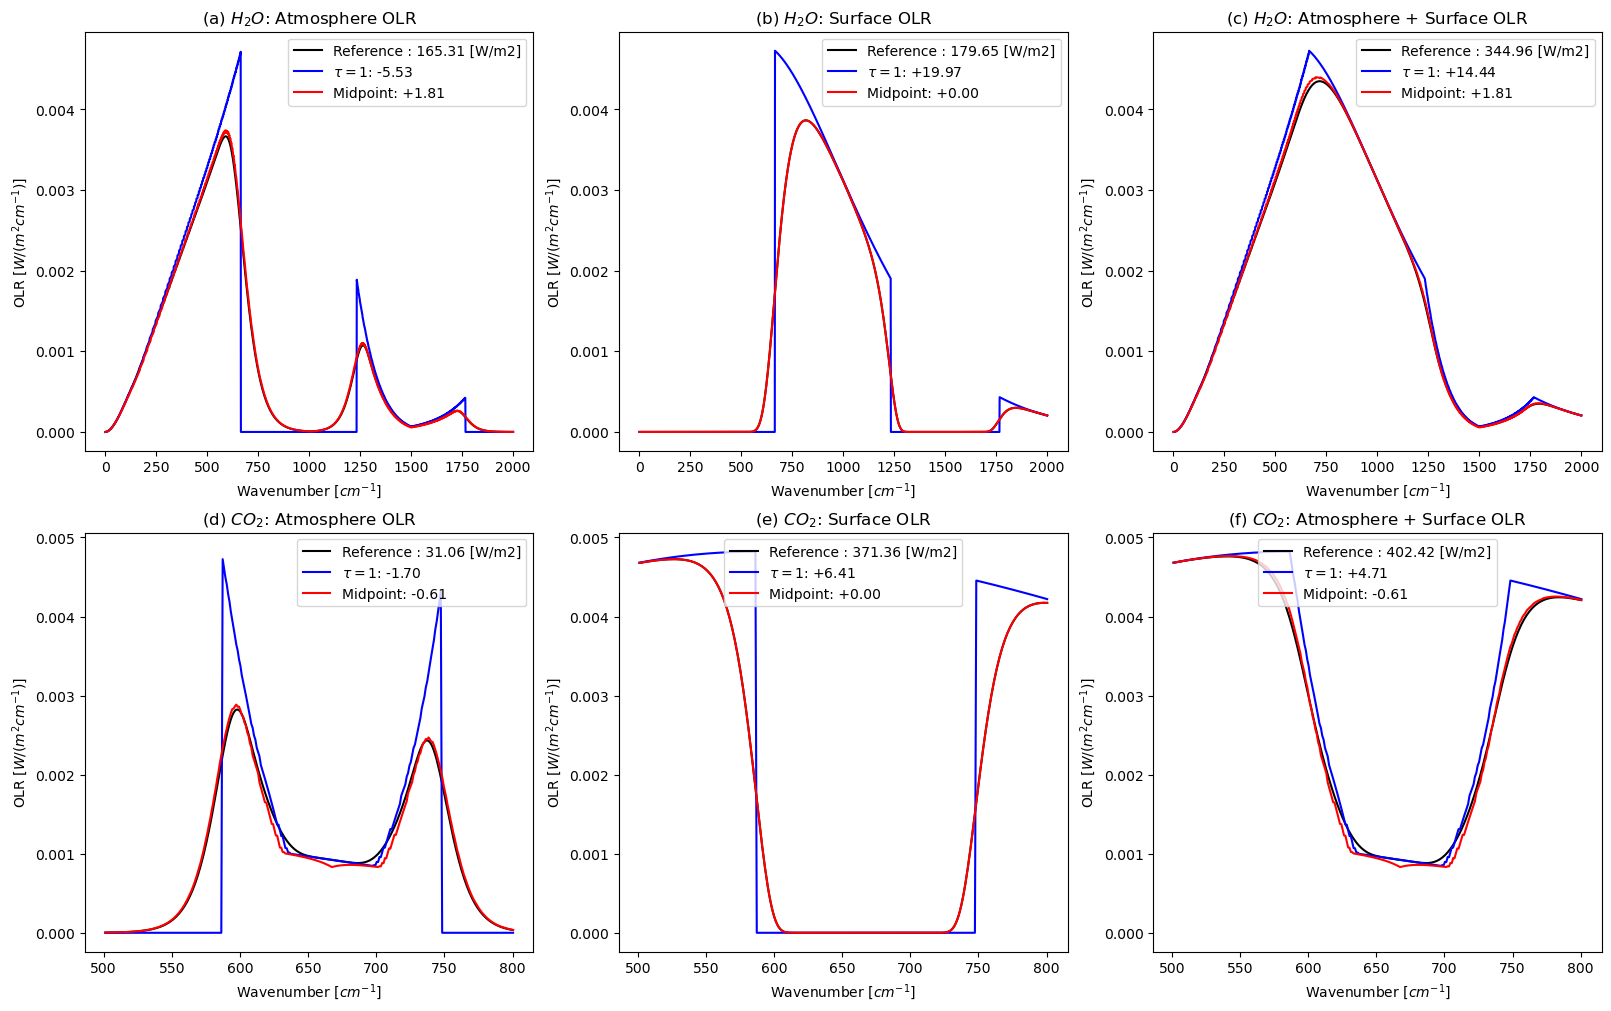

In [297]:
fig, ax = plt.subplots(2, 3, squeeze=False, figsize=(16,10), constrained_layout = True)

T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

pq = local_pq(p_half, q_half)

nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))

delta_nu = nu[1] - nu[0]


HR_nu, HR_surf = olr_h2o(p_half, q_half, T, T_half)
HR_nu_1, HR_surf_1 = olr_tau1_h2o(p_half, q_half, T)
HR_nu_transavg, HR_surf_transavg =  olr_transmid_h2o(p_half, q_half, T)

integrated_HR_nu = np.sum((HR_nu[1:] + HR_nu[:-1])/2 * delta_nu)
integrated_HR_surf = np.sum((HR_surf[1:] + HR_surf[:-1])/2 * delta_nu)

integrated_HR_nu_1 = np.sum((HR_nu_1[1:] + HR_nu_1[:-1])/2 * delta_nu)
integrated_HR_surf_1 = np.sum((HR_surf_1[1:] + HR_surf_1[:-1])/2 * delta_nu)

integrated_HR_nu_transavg = np.sum((HR_nu_transavg[1:] + HR_nu_transavg[:-1])/2 * delta_nu)
integrated_HR_surf_transavg = np.sum((HR_surf_transavg[1:] + HR_surf_transavg[:-1])/2 * delta_nu)

linestyle_ref = "-"
linestyle_transavg = "-"
linestyle_tau1 = "-"

ax[0,0].plot(nu/100, HR_nu , color = 'black', label = 'Reference', linestyle = linestyle_ref)
ax[0,0].plot(nu/100, HR_nu_1, color = 'blue', label = 'tau = 1', linestyle = linestyle_tau1)
ax[0,0].plot(nu/100, HR_nu_transavg, color = 'red', label = '(trans_top + trans_surf)/2', linestyle = linestyle_transavg)


ax[0,0].legend([f"Reference : {integrated_HR_nu:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_HR_nu_1) - (integrated_HR_nu):+.2f}", 
                rf"Midpoint: {(integrated_HR_nu_transavg) - (integrated_HR_nu):+.2f}"
               ],loc='upper right')

ax[0,1].plot(nu/100, HR_surf , color = 'black', label = 'Reference OLR', linestyle = linestyle_ref)
ax[0,1].plot(nu/100, HR_surf_1, color = 'blue', label = 'tau = 1', linestyle = linestyle_tau1)
ax[0,1].plot(nu/100, HR_surf_transavg, color = 'red', label = 'Average transmissivity', linestyle = linestyle_transavg)


ax[0,1].legend([f"Reference : {integrated_HR_surf:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_HR_surf_1) - (integrated_HR_surf):+.2f}", 
                rf"Midpoint: {(integrated_HR_surf_transavg) - (integrated_HR_surf):+.2f}"
               ],loc='upper right')

ax[0,2].plot(nu/100, HR_nu + HR_surf , color = 'black', label = 'Reference OLR', linestyle = linestyle_ref)
ax[0,2].plot(nu/100, HR_nu_1 + HR_surf_1, color = 'blue', label = 'tau = 1', linestyle = linestyle_tau1)
ax[0,2].plot(nu/100, HR_nu_transavg + HR_surf_transavg, color = 'red', label = 'Average transmissivity', linestyle = linestyle_transavg)



y_lim_max = np.max((HR_nu + HR_surf, HR_nu_transavg + HR_surf_transavg, HR_nu_1 + HR_surf_1))
y_lim_min = np.min((HR_nu + HR_surf, HR_nu_transavg + HR_surf_transavg, HR_nu_1 + HR_surf_1))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05


ax[0,2].legend([f"Reference : {integrated_HR_nu+integrated_HR_surf:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_HR_nu_1+integrated_HR_surf_1) - (integrated_HR_nu+integrated_HR_surf):+.2f}", 
                rf"Midpoint: {(integrated_HR_nu_transavg + integrated_HR_surf_transavg) - (integrated_HR_nu+integrated_HR_surf):+.2f}"
               ],loc='upper right')

ax[0,0].set_title(r"(a) $H_2 O$: Atmosphere OLR")
ax[0,1].set_title(r"(b) $H_2 O$: Surface OLR")
ax[0,2].set_title(r"(c) $H_2 O$: Atmosphere + Surface OLR")

for i in range(3):
    ax[0,i].set_ylabel(r'OLR $[W/(m^2 cm^{-1})]$')
    ax[0,i].set_xlabel(r'Wavenumber [$cm^{-1}$]')
    ax[0,i].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

nu_a = 500
nu_b = 800

nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
delta_nu = nu[1] - nu[0]
HR_nu, HR_surf = olr_co2(p_half, q_half, T, T_half)
HR_nu_1, HR_surf_1 = olr_tau1_co2(p_half, q_half, T)
HR_nu_transavg, HR_surf_transavg =  olr_transmid_co2(p_half, q_half, T)

integrated_HR_nu = np.sum((HR_nu[1:] + HR_nu[:-1])/2 * delta_nu)
integrated_HR_surf = np.sum((HR_surf[1:] + HR_surf[:-1])/2 * delta_nu)

integrated_HR_nu_1 = np.sum((HR_nu_1[1:] + HR_nu_1[:-1])/2 * delta_nu)
integrated_HR_surf_1 = np.sum((HR_surf_1[1:] + HR_surf_1[:-1])/2 * delta_nu)

integrated_HR_nu_transavg = np.sum((HR_nu_transavg[1:] + HR_nu_transavg[:-1])/2 * delta_nu)
integrated_HR_surf_transavg = np.sum((HR_surf_transavg[1:] + HR_surf_transavg[:-1])/2 * delta_nu)


ax[1,0].plot(nu[nu_a:nu_b]/100, HR_nu[nu_a:nu_b] , color = 'black', label = 'Reference OLR')
ax[1,0].plot(nu[nu_a:nu_b]/100, HR_nu_1[nu_a:nu_b], color = 'blue', label = 'tau = 1')
ax[1,0].plot(nu[nu_a:nu_b]/100, HR_nu_transavg[nu_a:nu_b], color = 'red', label = 'Average transmissivity')


ax[1,0].legend([f"Reference : {integrated_HR_nu:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_HR_nu_1) - (integrated_HR_nu):+.2f}", 
                rf"Midpoint: {(integrated_HR_nu_transavg) - (integrated_HR_nu):+.2f}"
               ],loc='upper right')

ax[1,1].plot(nu[nu_a:nu_b]/100, HR_surf[nu_a:nu_b] , color = 'black', label = 'Reference OLR')
ax[1,1].plot(nu[nu_a:nu_b]/100, HR_surf_1[nu_a:nu_b], color = 'blue', label = 'tau = 1')
ax[1,1].plot(nu[nu_a:nu_b]/100, HR_surf_transavg[nu_a:nu_b], color = 'red', label = 'Average transmissivity')

ax[1,1].legend([f"Reference : {integrated_HR_surf:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_HR_surf_1) - (integrated_HR_surf):+.2f}", 
                rf"Midpoint: {(integrated_HR_surf_transavg) - (integrated_HR_surf):+.2f}"
               ],loc='upper center')

ax[1,2].plot(nu[nu_a:nu_b]/100, HR_nu[nu_a:nu_b] + HR_surf[nu_a:nu_b] , color = 'black', label = 'Reference OLR')
ax[1,2].plot(nu[nu_a:nu_b]/100, HR_nu_1[nu_a:nu_b] + HR_surf_1[nu_a:nu_b], color = 'blue', label = 'tau = 1')
ax[1,2].plot(nu[nu_a:nu_b]/100, HR_nu_transavg[nu_a:nu_b] + HR_surf_transavg[nu_a:nu_b], color = 'red', label = 'Average transmissivity')


ax[1,2].legend([f"Reference : {integrated_HR_nu+integrated_HR_surf:.2f} [W/m2]", 
                rf"$\tau = 1$: {(integrated_HR_nu_1+integrated_HR_surf_1) - (integrated_HR_nu+integrated_HR_surf):+.2f}", 
                rf"Midpoint: {(integrated_HR_nu_transavg + integrated_HR_surf_transavg) - (integrated_HR_nu+integrated_HR_surf):+.2f}"
               ],loc='upper center')

y_lim_max = np.max((HR_nu + HR_surf, HR_nu_transavg + HR_surf_transavg, HR_nu_1 + HR_surf_1))
y_lim_min = np.min((HR_nu + HR_surf, HR_nu_transavg + HR_surf_transavg, HR_nu_1 + HR_surf_1))
y_lim_delta = (y_lim_max - y_lim_min) * 0.05


ax[1,0].set_title(r"(d) $CO_2$: Atmosphere OLR")
ax[1,1].set_title(r"(e) $CO_2$: Surface OLR")
ax[1,2].set_title(r"(f) $CO_2$: Atmosphere + Surface OLR")

for i in range(3):
    ax[1,i].set_ylabel(r'OLR $[W/(m^2 cm^{-1})]$')
    ax[1,i].set_xlabel(r'Wavenumber [$cm^{-1}$]')
    ax[1,i].set_ylim(y_lim_min - y_lim_delta, y_lim_max + y_lim_delta)

# plt.savefig('OLR_h2oco2.pdf')

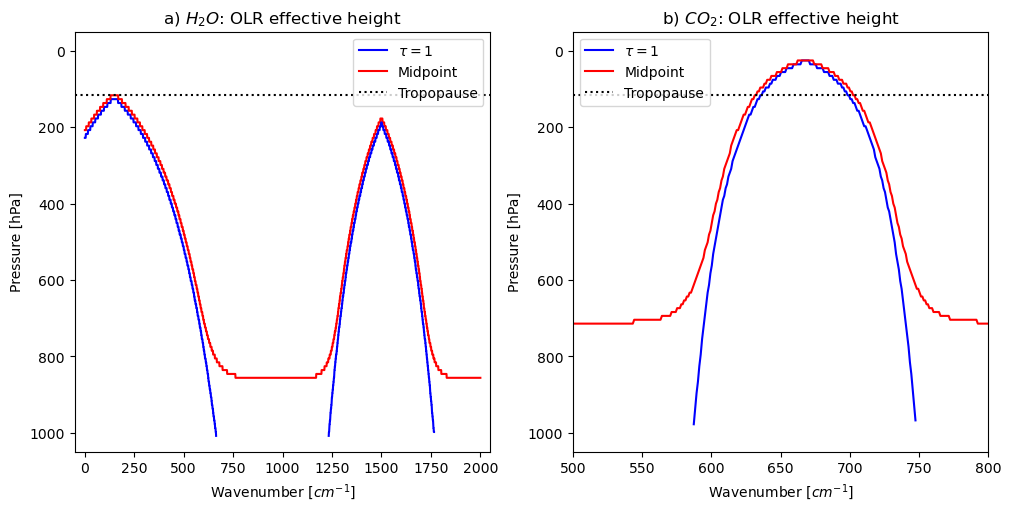

In [298]:
T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

pq = local_pq(p_half, q_half)
nu =  np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
tau_local = pq.reshape(-1,1) * k_h2o(nu).reshape(1,-1)
tau = np.cumsum(tau_local, axis = 0)
trans = np.exp(-tau)
trans_max = trans[0,:]
trans_min = trans[-1,:]
i_tau_midoint_h2o = np.argmin(np.abs(trans - (trans_max + trans_min)/2), axis = 0)
i_tau1_h2o = np.argmin(np.abs(tau - 1), axis = 0)
mask_1_h2o_left = ~((tau[-1] < 1) | (nu >= 100000))
mask_1_h2o_right = ~((tau[-1] < 1) | (nu < 100000))



pq = local_pq(p_half, qco2 + np.zeros_like(q_half))
nu =  np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))
tau_local = pq.reshape(-1,1) * k_co2(nu).reshape(1,-1)
tau = np.cumsum(tau_local, axis = 0)
trans = np.exp(-tau)
trans_max = trans[0,:]
trans_min = trans[-1,:]
i_tau_midoint_co2 = np.argmin(np.abs(trans - (trans_max + trans_min)/2), axis = 0)
i_tau1_co2 = np.argmin(np.abs(tau - 1), axis = 0)
mask_1_co2 = ~(tau[-1] < 1)


fig, ax = plt.subplots(1,2, figsize=(10,5), constrained_layout = True)


ax[0].plot(nu[mask_1_h2o_left]/100,p[i_tau1_h2o][mask_1_h2o_left]/100, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0].plot(nu/100,p[i_tau_midoint_h2o]/100, c='red', label="Midpoint", linestyle = "-")
ax[0].hlines(p_tp/100, -50,2050, color = 'black', linestyle = ':', label = 'Tropopause')
ax[0].legend()
ax[0].plot(nu[mask_1_h2o_right]/100,p[i_tau1_h2o][mask_1_h2o_right]/100, c='blue', label=r'$\tau = 1$', linestyle = "-")


ax[0].set_xlim(-50,2050)
ax[0].set_ylim(-50,1050)

ax[0].invert_yaxis()

ax[0].set_title(r'a) $H_2 O$: OLR effective height')
ax[0].set_xlabel(r'Wavenumber $[cm^{-1}]$')
ax[0].set_ylabel('Pressure [hPa]')


nu_a = 500
nu_b = 800

ax[1].plot(nu[mask_1_co2]/100,p[i_tau1_co2][mask_1_co2]/100, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1].plot(nu[nu_a:nu_b]/100,p[i_tau_midoint_co2][nu_a:nu_b]/100, c='red', label="Midpoint", linestyle = "-")

ax[1].hlines(p_tp/100, 500,800, color = 'black', linestyle = ':', label = 'Tropopause')

ax[1].legend()
ax[1].set_xlim(500,800)
ax[1].set_ylim(-50,1050)

ax[1].invert_yaxis()

ax[1].set_title(r'b) $CO_2$: OLR effective height')
ax[1].set_xlabel(r'Wavenumber $[cm^{-1}]$')
ax[1].set_ylabel('Pressure [hPa]')
ax[1].legend()
# plt.savefig('nus_tau1_transmid_h2oco2.pdf')

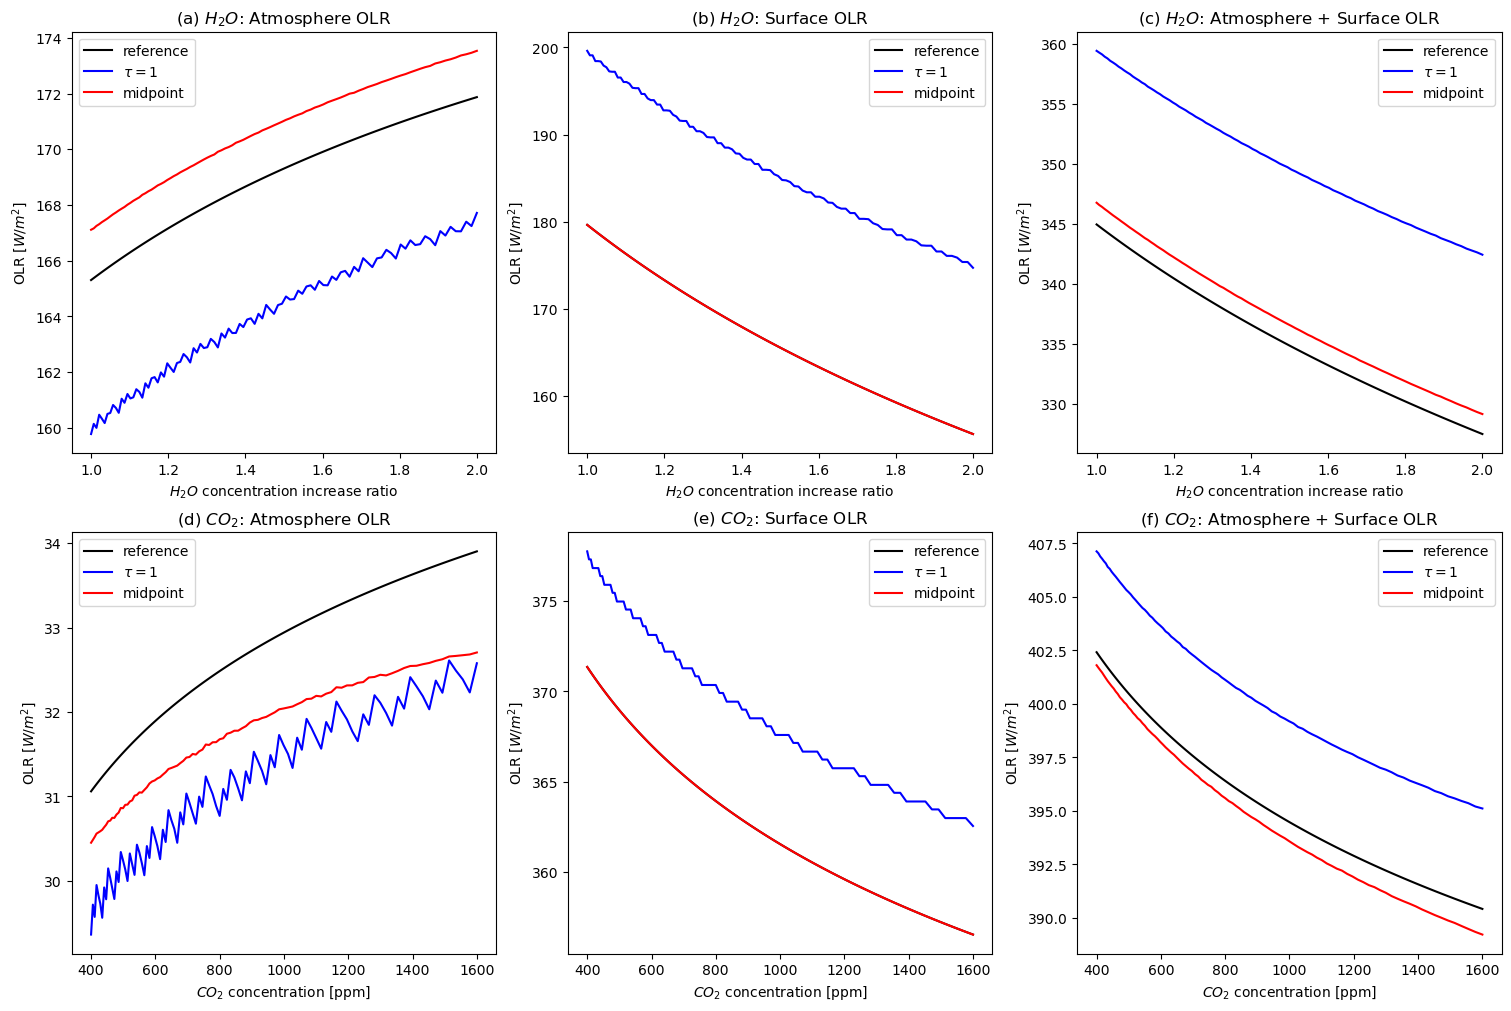

In [299]:
T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6

nu = np.linspace(nu_min, nu_max, int((nu_max - nu_min + 1)/100))


integrated_HR_nu_h2o = np.zeros(101)
integrated_HR_surf_h2o = np.zeros(101)
integrated_HR_nu_1_h2o = np.zeros(101)
integrated_HR_surf_1_h2o = np.zeros(101)
integrated_HR_nu_transavg_h2o = np.zeros(101)
integrated_HR_surf_transavg_h2o = np.zeros(101)
integrated_HR_nu_1_h2o_highres = np.zeros(101)
integrated_HR_surf_1_h2o_highres = np.zeros(101)
ratio_increase  = np.array([1 * 2 **(n/100) for n in range(101)])
qco2 = 400e-6
for n in range(101):
    q_half2 = ratio_increase[n] * q_half
    HR_nu, HR_surf = olr_h2o(p_half, q_half2, T, T_half)
    HR_nu_1, HR_surf_1 = olr_tau1_h2o(p_half, q_half2, T)
    HR_nu_transavg, HR_surf_transavg =  olr_transmid_h2o(p_half, q_half2, T)
    
    
    integrated_HR_nu_h2o[n] = np.sum((HR_nu[1:] + HR_nu[:-1])/2 * delta_nu)
    integrated_HR_surf_h2o[n] = np.sum((HR_surf[1:] + HR_surf[:-1])/2 * delta_nu)
    
    integrated_HR_nu_1_h2o[n] = np.sum((HR_nu_1[1:] + HR_nu_1[:-1])/2 * delta_nu)
    integrated_HR_surf_1_h2o[n] = np.sum((HR_surf_1[1:] + HR_surf_1[:-1])/2 * delta_nu)
    
    integrated_HR_nu_transavg_h2o[n] = np.sum((HR_nu_transavg[1:] + HR_nu_transavg[:-1])/2 * delta_nu)
    integrated_HR_surf_transavg_h2o[n] = np.sum((HR_surf_transavg[1:] + HR_surf_transavg[:-1])/2 * delta_nu)

integrated_HR_nu_co2 = np.zeros(101)
integrated_HR_surf_co2 = np.zeros(101)
integrated_HR_nu_1_co2 = np.zeros(101)
integrated_HR_surf_1_co2 = np.zeros(101)
integrated_HR_nu_transavg_co2 = np.zeros(101)
integrated_HR_surf_transavg_co2 = np.zeros(101)
q_co2 = np.array([400e-6 * 2 **(n/50) for n in range(101)])
for n in range(101):
    qco2 = q_co2[n]
    HR_nu, HR_surf = olr_co2(p_half, q_half, T, T_half)
    HR_nu_1, HR_surf_1 = olr_tau1_co2(p_half, q_half, T)
    HR_nu_transavg, HR_surf_transavg =  olr_transmid_co2(p_half, q_half, T)

    
    integrated_HR_nu_co2[n] = np.sum((HR_nu[1:] + HR_nu[:-1])/2 * delta_nu)
    integrated_HR_surf_co2[n] = np.sum((HR_surf[1:] + HR_surf[:-1])/2 * delta_nu)
    
    integrated_HR_nu_1_co2[n] = np.sum((HR_nu_1[1:] + HR_nu_1[:-1])/2 * delta_nu)
    integrated_HR_surf_1_co2[n] = np.sum((HR_surf_1[1:] + HR_surf_1[:-1])/2 * delta_nu)
    
    integrated_HR_nu_transavg_co2[n] = np.sum((HR_nu_transavg[1:] + HR_nu_transavg[:-1])/2 * delta_nu)
    integrated_HR_surf_transavg_co2[n] = np.sum((HR_surf_transavg[1:] + HR_surf_transavg[:-1])/2 * delta_nu)

fig, ax = plt.subplots(2,3, figsize=(15,10), constrained_layout = True)

ax[0,0].plot(ratio_increase, integrated_HR_nu_h2o, c='black', label='reference',linestyle = "-")
ax[0,0].plot(ratio_increase, integrated_HR_nu_1_h2o, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0,0].plot(ratio_increase, integrated_HR_nu_transavg_h2o, c='red', label='midpoint', linestyle = "-")
ax[0,0].legend()

ax[0,1].plot(ratio_increase, integrated_HR_surf_h2o, c='black', label='reference',linestyle = "-")
ax[0,1].plot(ratio_increase, integrated_HR_surf_1_h2o, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0,1].plot(ratio_increase, integrated_HR_surf_transavg_h2o, c='red', label='midpoint', linestyle = "-")
ax[0,1].legend()

ax[0,2].plot(ratio_increase, integrated_HR_nu_h2o + integrated_HR_surf_h2o, c='black', label='reference',linestyle = "-")
ax[0,2].plot(ratio_increase, integrated_HR_nu_1_h2o + integrated_HR_surf_1_h2o, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0,2].plot(ratio_increase, integrated_HR_nu_transavg_h2o + integrated_HR_surf_transavg_h2o, c='red', label='midpoint', linestyle = "-")
ax[0,2].legend()

ax[0,0].set_title(r"(a) $H_2 O$: Atmosphere OLR")
ax[0,1].set_title(r"(b) $H_2 O$: Surface OLR")
ax[0,2].set_title(r"(c) $H_2 O$: Atmosphere + Surface OLR")

for i in range(3):
    ax[0,i].set_xlabel(r"$H_2 O$ concentration increase ratio")
    ax[0,i].set_ylabel(r'OLR $[W/m^2]$')

ax[1,0].plot(q_co2 * 1e6, integrated_HR_nu_co2, c='black', label='reference',linestyle = "-")
ax[1,0].plot(q_co2 * 1e6, integrated_HR_nu_1_co2, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1,0].plot(q_co2 * 1e6, integrated_HR_nu_transavg_co2, c='red', label='midpoint', linestyle = "-")
ax[1,0].legend()

ax[1,1].plot(q_co2 * 1e6, integrated_HR_surf_co2, c='black', label='reference',linestyle = "-")
ax[1,1].plot(q_co2 * 1e6, integrated_HR_surf_1_co2, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1,1].plot(q_co2 * 1e6, integrated_HR_surf_transavg_co2, c='red', label='midpoint', linestyle = "-")
ax[1,1].legend()

ax[1,2].plot(q_co2 * 1e6, integrated_HR_nu_co2 + integrated_HR_surf_co2, c='black', label='reference',linestyle = "-")
ax[1,2].plot(q_co2 * 1e6, integrated_HR_nu_1_co2 + integrated_HR_surf_1_co2, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1,2].plot(q_co2 * 1e6, integrated_HR_nu_transavg_co2 + integrated_HR_surf_transavg_co2, c='red', label='midpoint', linestyle = "-")
ax[1,2].legend()

ax[1,0].set_title(r"(d) $CO_2$: Atmosphere OLR")
ax[1,1].set_title(r"(e) $CO_2$: Surface OLR")
ax[1,2].set_title(r"(f) $CO_2$: Atmosphere + Surface OLR")

for i in range(3):
    ax[1,i].set_xlabel(r"$CO_2$ concentration [ppm]")
    ax[1,i].set_ylabel(r'OLR $[W/m^2]$')

# plt.savefig('olr_sensitivity_h2oco2.pdf')


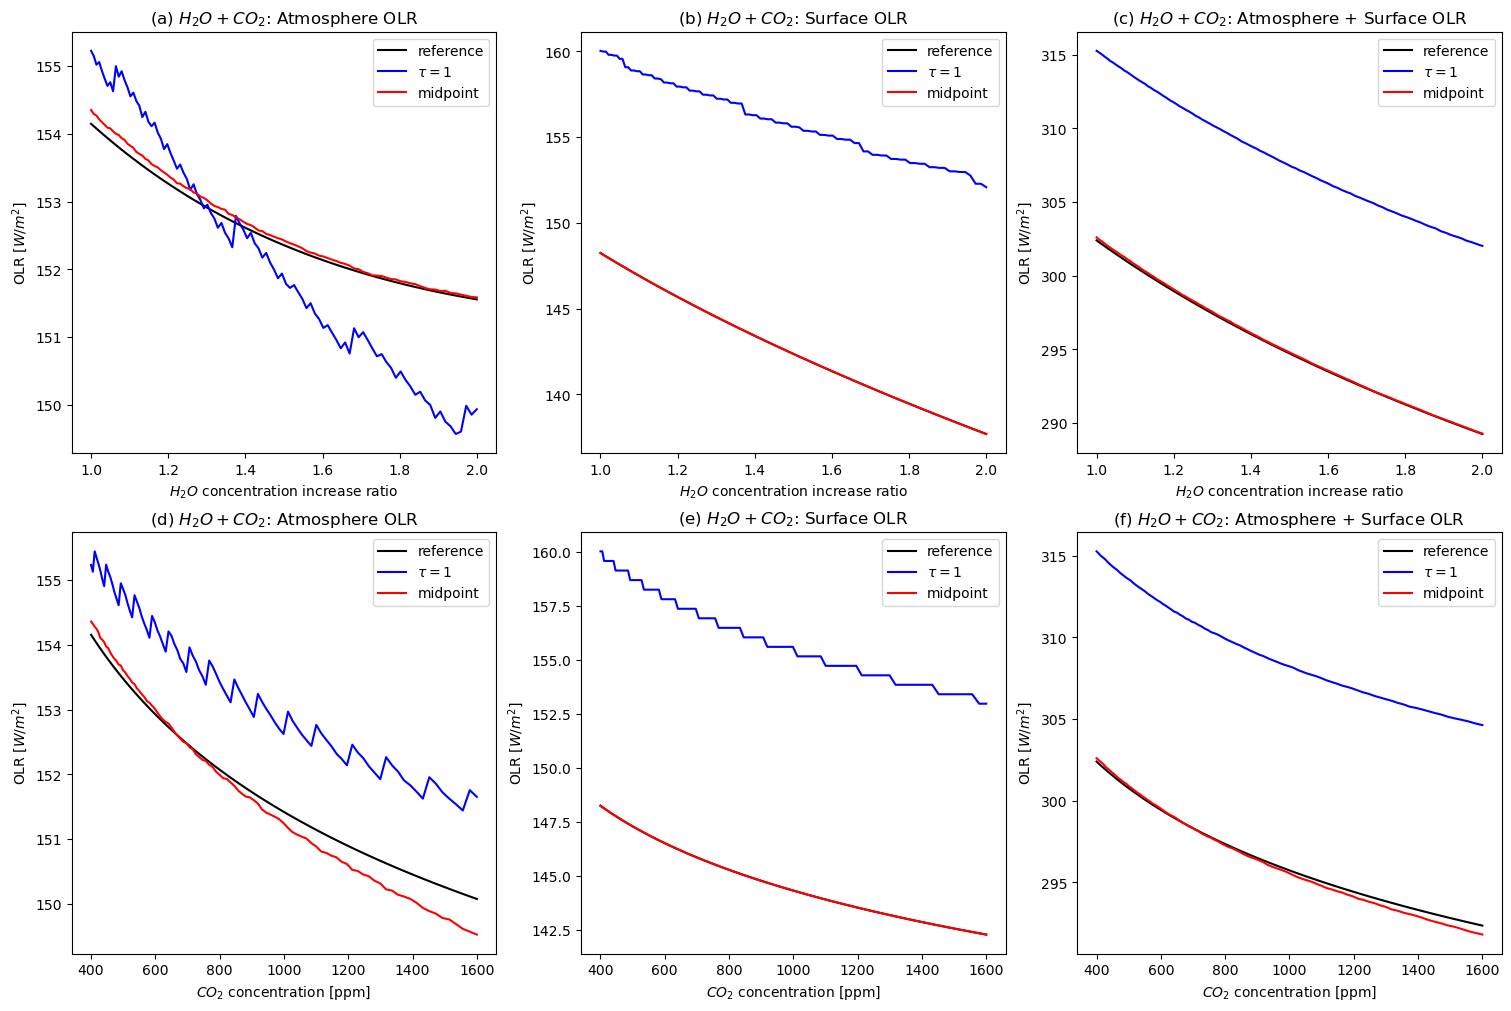

In [300]:
T, T_half, q, q_half, p, p_half = atmosphere(Ts = 300, RH = 0.5)
qco2 = 400e-6


integrated_HR_nu_h2oco2_co2up_nocnt = np.zeros(101)
integrated_HR_surf_h2oco2_co2up_nocnt = np.zeros(101)
integrated_HR_nu_1_h2oco2_co2up_nocnt = np.zeros(101)
integrated_HR_surf_1_h2oco2_co2up_nocnt = np.zeros(101)
integrated_HR_nu_transavg_h2oco2_co2up_nocnt = np.zeros(101)
integrated_HR_surf_transavg_h2oco2_co2up_nocnt = np.zeros(101)
q_co2 = np.array([400e-6 * 2 **(n/50) for n in range(101)])

for n in range(101):
    qco2 = q_co2[n]
    HR_nu, HR_surf = olr_h2o_co2(p_half, q_half, T, T_half)
    HR_nu_1, HR_surf_1 = olr_tau1_h2o_co2(p_half, q_half, T)
    HR_nu_transavg, HR_surf_transavg =  olr_transmid_h2o_co2(p_half, q_half, T)
    
    integrated_HR_nu_h2oco2_co2up_nocnt[n] = np.sum((HR_nu[1:] + HR_nu[:-1])/2 * delta_nu)
    integrated_HR_surf_h2oco2_co2up_nocnt[n] = np.sum((HR_surf[1:] + HR_surf[:-1])/2 * delta_nu)
    
    integrated_HR_nu_1_h2oco2_co2up_nocnt[n] = np.sum((HR_nu_1[1:] + HR_nu_1[:-1])/2 * delta_nu)
    integrated_HR_surf_1_h2oco2_co2up_nocnt[n] = np.sum((HR_surf_1[1:] + HR_surf_1[:-1])/2 * delta_nu)
    
    integrated_HR_nu_transavg_h2oco2_co2up_nocnt[n] = np.sum((HR_nu_transavg[1:] + HR_nu_transavg[:-1])/2 * delta_nu)
    integrated_HR_surf_transavg_h2oco2_co2up_nocnt[n] = np.sum((HR_surf_transavg[1:] + HR_surf_transavg[:-1])/2 * delta_nu)

qco2 = 400e-6
integrated_HR_nu_h2oco2_h2oup_nocnt = np.zeros(101)
integrated_HR_surf_h2oco2_h2oup_nocnt = np.zeros(101)
integrated_HR_nu_1_h2oco2_h2oup_nocnt = np.zeros(101)
integrated_HR_surf_1_h2oco2_h2oup_nocnt = np.zeros(101)
integrated_HR_nu_transavg_h2oco2_h2oup_nocnt = np.zeros(101)
integrated_HR_surf_transavg_h2oco2_h2oup_nocnt = np.zeros(101)
ratio_increase  = np.array([1 * 2 **(n/100) for n in range(101)])
for n in range(101):
    q_half2 = ratio_increase[n] * q_half
    HR_nu, HR_surf = olr_h2o_co2(p_half, q_half2, T, T_half)
    HR_nu_1, HR_surf_1 = olr_tau1_h2o_co2(p_half, q_half2, T)
    HR_nu_transavg, HR_surf_transavg =  olr_transmid_h2o_co2(p_half, q_half2, T)
    
    integrated_HR_nu_h2oco2_h2oup_nocnt[n] = np.sum((HR_nu[1:] + HR_nu[:-1])/2 * delta_nu)
    integrated_HR_surf_h2oco2_h2oup_nocnt[n] = np.sum((HR_surf[1:] + HR_surf[:-1])/2 * delta_nu)
    
    integrated_HR_nu_1_h2oco2_h2oup_nocnt[n] = np.sum((HR_nu_1[1:] + HR_nu_1[:-1])/2 * delta_nu)
    integrated_HR_surf_1_h2oco2_h2oup_nocnt[n] = np.sum((HR_surf_1[1:] + HR_surf_1[:-1])/2 * delta_nu)
    
    integrated_HR_nu_transavg_h2oco2_h2oup_nocnt[n] = np.sum((HR_nu_transavg[1:] + HR_nu_transavg[:-1])/2 * delta_nu)
    integrated_HR_surf_transavg_h2oco2_h2oup_nocnt[n] = np.sum((HR_surf_transavg[1:] + HR_surf_transavg[:-1])/2 * delta_nu)

fig, ax = plt.subplots(2,3, figsize=(15,10), constrained_layout = True)

ax[0,0].plot(ratio_increase, integrated_HR_nu_h2oco2_h2oup_nocnt, c='black', label='reference',linestyle = "-")
ax[0,0].plot(ratio_increase, integrated_HR_nu_1_h2oco2_h2oup_nocnt, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0,0].plot(ratio_increase, integrated_HR_nu_transavg_h2oco2_h2oup_nocnt, c='red', label='midpoint', linestyle = "-")
ax[0,0].legend()

ax[0,1].plot(ratio_increase, integrated_HR_surf_h2oco2_h2oup_nocnt, c='black', label='reference',linestyle = "-")
ax[0,1].plot(ratio_increase, integrated_HR_surf_1_h2oco2_h2oup_nocnt, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0,1].plot(ratio_increase, integrated_HR_surf_transavg_h2oco2_h2oup_nocnt, c='red', label='midpoint', linestyle = "-")
ax[0,1].legend()

ax[0,2].plot(ratio_increase, integrated_HR_nu_h2oco2_h2oup_nocnt + integrated_HR_surf_h2oco2_h2oup_nocnt, c='black', label='reference',linestyle = "-")
ax[0,2].plot(ratio_increase, integrated_HR_nu_1_h2oco2_h2oup_nocnt + integrated_HR_surf_1_h2oco2_h2oup_nocnt, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[0,2].plot(ratio_increase, integrated_HR_nu_transavg_h2oco2_h2oup_nocnt + integrated_HR_surf_transavg_h2oco2_h2oup_nocnt, c='red', label='midpoint', linestyle = "-")
ax[0,2].legend()

ax[0,0].set_title(r"(a) $H_2 O + CO_2$: Atmosphere OLR")
ax[0,1].set_title(r"(b) $H_2 O + CO_2$: Surface OLR")
ax[0,2].set_title(r"(c) $H_2 O + CO_2$: Atmosphere + Surface OLR")

for i in range(3):
    ax[0,i].set_xlabel(r"$H_2 O$ concentration increase ratio")
    ax[0,i].set_ylabel(r'OLR $[W/m^2]$')


ax[1,0].plot(q_co2 * 1e6, integrated_HR_nu_h2oco2_co2up_nocnt, c='black', label='reference',linestyle = "-")
ax[1,0].plot(q_co2 * 1e6, integrated_HR_nu_1_h2oco2_co2up_nocnt, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1,0].plot(q_co2 * 1e6, integrated_HR_nu_transavg_h2oco2_co2up_nocnt, c='red', label='midpoint', linestyle = "-")
ax[1,0].legend()

ax[1,1].plot(q_co2 * 1e6, integrated_HR_surf_h2oco2_co2up_nocnt, c='black', label='reference',linestyle = "-")
ax[1,1].plot(q_co2 * 1e6, integrated_HR_surf_1_h2oco2_co2up_nocnt, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1,1].plot(q_co2 * 1e6, integrated_HR_surf_transavg_h2oco2_co2up_nocnt, c='red', label='midpoint', linestyle = "-")
ax[1,1].legend()

ax[1,2].plot(q_co2 * 1e6, integrated_HR_nu_h2oco2_co2up_nocnt + integrated_HR_surf_h2oco2_co2up_nocnt, c='black', label='reference',linestyle = "-")
ax[1,2].plot(q_co2 * 1e6, integrated_HR_nu_1_h2oco2_co2up_nocnt + integrated_HR_surf_1_h2oco2_co2up_nocnt, c='blue', label=r'$\tau = 1$', linestyle = "-")
ax[1,2].plot(q_co2 * 1e6, integrated_HR_nu_transavg_h2oco2_co2up_nocnt + integrated_HR_surf_transavg_h2oco2_co2up_nocnt, c='red', label='midpoint', linestyle = "-")
ax[1,2].legend()

ax[1,0].set_title(r"(d) $H_2O + CO_2$: Atmosphere OLR")
ax[1,1].set_title(r"(e) $H_2O + CO_2$: Surface OLR")
ax[1,2].set_title(r"(f) $H_2O + CO_2$: Atmosphere + Surface OLR")

for i in range(3):
    ax[1,i].set_xlabel(r"$CO_2$ concentration [ppm]")
    ax[1,i].set_ylabel(r'OLR $[W/m^2]$')

# plt.savefig('olr_sensitivity_h2o_plus_co2.pdf')
